# FINAL THESIS RUN: supervised vs pseudo-labelling vs TF-C, with a two-logger unlabelled pool

**Conditions**
| id | what | role |
|---|---|---|
| C0 | supervised baseline | reference |
| C0+ | baseline + the same extra labelled epochs as one pseudo round (fresh restart from baseline per round, same labelled draws) | "is it just more training?" control |
| C0n | supervised with noise augmentation estimated from Logger B | cheap robustness result, no pseudo-labels |
| C1 | probability seeding (calibrated, per-class precision-targeted thresholds) | pseudo-label |
| C2 | centroid seeding (pre-classifier embedding, VAL-refit radii) | pseudo-label |
| C3 | TF-C pre-training on the unlabelled pool (+ labelled TRAIN windows), then supervised fine-tune of the **same dense V-Net** | self-supervised |

**Factors**: unlabelled pool `A` (176 h, controlled comparison) / `B` (1,722 h) / `AB`; sampling `natural` vs `balanced` (50/50 by logger); pool fraction; labelled-animal fraction; seeds; gated vs ungated.

**Design decisions / critique to keep in the thesis text**
1. **Preprocessing changes the labelled data too.** The 0.2 Hz high-pass + median/IQR scaling is applied identically to labelled A, unlabelled A and unlabelled B, so *all baselines are retrained* on it. Numbers are not comparable with earlier runs; the legacy-vs-new domain-AUC table is the justification.
2. **Pseudo-label cost is capped**: pseudo-labels are produced on a fixed budget of `N_CAND` candidate windows drawn from the chosen pool (not the whole 1,722 h), so U_B costs the same as U_A. Scaling is then studied explicitly.
3. **C3 is made comparable**: the TF-C time encoder is a full-width dense V-Net; after pre-training its weights initialise the identical dense V-Net used by C0 (fresh classifier, same recipe, same early stopping). The original TF-C 1.25 s segment head is *not* used here, so C3 vs C0 is not confounded by output granularity. C3 gets extra compute (pre-training) that C0+ does not match; state this.
4. **Gated results are model selection on 2 animals** (noisy). Both gated and ungated (fixed final round) are reported; ungated is primary.
5. **Inference**: fold-level values (seeds averaged within fold) are the unit of analysis; Wilcoxon + paired bootstrap + effect sizes, Holm correction, Friedman + Nemenyi. Folds share training animals, so p-values stay descriptive.
6. Pseudo-label quality is measured on held-out labelled animals (VAL, in-sample for calibration/radii; TEST, honest, diagnostic only, never used for selection).
7. Label sampler is a re-implementation of the class-balanced window sampler (same class sampling weights, windows start within one window length of a class timestep); it is not bit-identical to earlier runs.

Set env `THESIS_PROFILE=smoke` for a tiny pipeline check; default is `final`. **Not yet executed.**

In [10]:
import os
WORKER, N_WORKERS = 1, 2          
_n = max(1, (os.cpu_count() or 2) // N_WORKERS)
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS"): os.environ[_v] = str(_n)

In [11]:
import re, json, copy, time, pickle, random, itertools, warnings, datetime, math
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from scipy import signal, stats
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GroupKFold, cross_val_predict

torch.set_num_threads(_n)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)

dev = torch.device("xpu" if hasattr(torch, "xpu") and torch.xpu.is_available()
                   else "cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev)

PROFILE = os.environ.get("THESIS_PROFILE", "final")

PROF = dict(
    final=dict(SEEDS=[0, 1, 2], LE_FRACS=[0.1, 0.25, 0.5], LE_SEEDS=[0], SC_FRACS=[0.1, 0.5], SC_SEEDS=[0] ,
               N_FOLDS=None, EPOCHS=150, PAT=20, N_TRAIN=10000, N_VAL=8000, PS_ITERS=3, PS_EPOCHS=15,
               N_CAND=40000, PRE_STEPS=4000, PRE_BS=32),
    smoke=dict(SEEDS=[0], LE_FRACS=[0.25], LE_SEEDS=[0], SC_FRACS=[0.25], SC_SEEDS=[0],
               N_FOLDS=2, EPOCHS=2, PAT=2, N_TRAIN=640, N_VAL=320, PS_ITERS=2, PS_EPOCHS=1,
               N_CAND=1500, PRE_STEPS=100, PRE_BS=8),
)[PROFILE]
globals().update(PROF)

SEED = 42
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
    if hasattr(torch, "xpu") and torch.xpu.is_available(): torch.xpu.manual_seed_all(s)

# ---- classes: (name, behaviour codes, sampling_weight, loss_weight)
CL = [("Other", None, 1, 0.1), ("Breathing", [1, 2, 40], 1, 1), ("Feeding", [3,4,5,6,7,11,12,13,18,19,20,21], 2, 2),
      ("Gliding", [16, 17], 3, 1), ("Resting", [29,30,31,32], 0.5, 1), ("Scratching", [34,35,36], 2, 2),
      ("Swimming", [42,45,48,43,46,49,27,44,47,50,56,52,54,55], 0.5, 1)]
CLASS_NAMES = [c[0] for c in CL]; NC = len(CL)
TARGETS = ["Feeding", "Scratching", "Gliding"]; TARGET_IDS = [CLASS_NAMES.index(n) for n in TARGETS]
SAMPLING_W = np.array([c[2] for c in CL], float)
ponde = torch.tensor([c[3] for c in CL], dtype=torch.float32); ponde /= ponde.sum()

DESC_A, DESC_B_LAB, DESC_UNLAB_A, DESC_UNLAB_B = [1,2,3,4,5,6,25], [0,1,2,3,4,5,24], [0,1,2,3,4,5,9], [0,1,2,3,4,5]
COL_BEH, DT = 27, 0.05
FS = 1 / DT
W = int(40 / DT)            # 800
SUB = 50                    # sub-window for centroid embeddings
DIR_IN, DIR_A, DIR_B = "Data", "Data/TV_processed_unlabelled", "Data/TV_Martinique_AGM_unlabelled"
PRESSURE_DIFF_S = 2.0

# model / training
LR, BS, DEPTH, DROPOUT = 1e-4, 32, 32, 0.5
PSEUDO_LR, PSEUDO_W, PSEUDO_SMOOTH, PSEUDO_PASSES = 1e-4, 0.10, 0.10, 2.0
MAX_PER_CLASS, MIN_CONF = 1000, 5
TS_CAP_FLOOR, TS_CAP_RATIO = 20_000, 1.0
# calibration / thresholds (C1)
TARGET_PREC = {"Feeding": .9, "Scratching": .9, "Gliding": .9, "default": .95}
THR_MIN_PRED, THR_MIN_CORRECT, THR_FALLBACK, THR_DISABLED, THR_FLOOR = 500, 300, .99, 1.01, .60
# centroid (C2)
C_PCT = {"Other": 90, "Feeding": 90, "Scratching": 90, "Breathing": 80, "Gliding": 85, "Resting": 80, "Swimming": 80}
C_PUR = {"Other": .75, "Feeding": .85, "Scratching": .75, "Breathing": .90, "Gliding": .85, "Resting": .90, "Swimming": .90}
C_MINPTS = {"Other": 15, "Feeding": 15, "Scratching": 15, "Breathing": 40, "Gliding": 15, "Resting": 40, "Swimming": 40}
C_COV = {"Other": .35, "Feeding": .35, "Scratching": .35}   # default .5
C_INFLATE, C_VAL_MIN_PTS, C_VAL_MIN_CORRECT = 3.0, 30, 15
# gate
GATE_MARGIN, GATE_MACRO_TOL = 0.0, 0.01
# TF-C
TFC_TAU, TFC_LAM, TFC_DELTA, SEG = 0.2, 0.5, 1.0, 25
NSEG = W // SEG; NF = SEG // 2 + 1; NCH = 7

#OUT = Path("Model_results") / f"FINAL_{datetime.date.today():%Y_%m_%d}_{PROFILE}"
OUT = Path(os.environ.get("OUT_DIR", "Model_results/FINAL_2026_10_11_final"))
(OUT / "units").mkdir(parents=True, exist_ok=True); (OUT / "fig").mkdir(exist_ok=True)
print("output:", OUT)



device: cuda
output: Model_results/FINAL_2026_10_11_final


## 1. Recordings and individuals

In [12]:
NAMES_ALL = ['CC-07-48_18-02-2019','CC-07-48_06-10-2018','CC-07-48_04-10-2018','CC-07-115_13-05-2019','CC-07-115_14-05-2019',
 'CC-07-48_08-04-2019_1','CC-07-48_08-04-2019_2','CC-07-48_08-04-2019_3','CC-07-48_22-05-2018','CC-07-108_11-02-2019',
 'CC-07-59_20-05-2018','CC-07-47_14-02-2018','CC-07-48_10-10-2018','CC-07-48_08-10-2018','CC-07-48_26-05-2018',
 'CC-07-107_11-02-2019','CC-09-72_04-11-2022']
NAMES_UNLAB_A = ['20211130-203207-CC-09-29_TV_112021','20211114-120603-CC-09-28_TV_102021','20211122-104139-CC-09-28_TV_102021',
 '20220414-002025-CC-09-80','20211108-055826-CC-09-28_TV_102021','20211024-141045-CC-09-29_TV_102021',
 '20211101-081704-CC-09-28_TV_102021','20211102-115134-CC-09-29_TV_102021','20211113-213025-CC-09-29_TV_112021',
 '20211107-072758-CC-09-29_TV_102021','20220508-195728-CC-09-80','20220114-125839-CC-09-29_TV_012022',
 '20220421-211441-CC-09-80','20211121-203649-CC-09-29_TV_112021']
NAMES_UNLAB_B = ["AGM1_TV_AN_08122020","AGM1_TV_AN_15122020","AGM1_TV_AN_19012021","AGM1_TV_GA_07052021","AGM1_TV_GA_23122020",
 "AGM1_TV_GA_25052021","AGM1_TV_GA_30042021","AGM2_TV_AN_08122020_1","AGM2_TV_AN_15122020_2","AGM2_TV_AN_29012021",
 "AGM2_TV_GA_23122020","AGM4_TV_AN_08122020","AGM4_TV_AN_19012021_2","AGM4_TV_AN_29012021","AGM4_TV_GA_23122020",
 "AGM4_TV_GA_30042021","AGM5_TV_GA_22042021","AGM5_TV_GA_30042021","AGM6_TV_GA_07052021","AGM7_TV_AN_25052021_1"]
OVR = {'CC-07-115_13-05-2019': 'CC-07-115', 'CC-07-115_14-05-2019': 'CC-07-115'}
def individual_id_of(n): return OVR.get(n, re.sub(r'_\d+$', '', n))
IND2NAMES = defaultdict(list)
for n in NAMES_ALL: IND2NAMES[individual_id_of(n)].append(n)
INDIVIDUALS = sorted(IND2NAMES)
assert len(INDIVIDUALS) == 14, len(INDIVIDUALS)

## 2. Loading (raw), legacy features for the comparability baseline, then robust preprocessing
Robust pipeline for **every** source: 0.2 Hz zero-phase high-pass on the 6 motion channels (removes drift / gravity offset), then per-recording median/IQR scaling of all 7 channels, clipped at ±10. Raw std/diff summary statistics are never fed to a model.

In [13]:
def resample_pressure_diff(mes, diff_s=PRESSURE_DIFF_S, depth_col=9):
    mes = mes.copy()
    chg = np.where(np.diff(mes.iloc[:, depth_col]) != 0)[0]
    mes['Pressure_corr'] = np.nan; mes.iloc[chg, -1] = mes.iloc[chg, depth_col]
    mes['Pressure_corr'] = mes['Pressure_corr'].interpolate(method='linear').bfill()
    k = max(1, int(round(diff_s / (np.median(np.diff(chg)) * DT))))
    mes['Pressure_diff'] = np.nan; mes.iloc[chg, -1] = mes.iloc[chg, depth_col].diff(k)
    mes['Pressure_diff'] = mes['Pressure_diff'].interpolate(method='linear').bfill()
    return mes

def load_labelled(names):
    mats, labs = {}, {}
    for n in names:
        pa, pb = f"{DIR_IN}/out_A_09062025/{n}.npy", f"{DIR_IN}/out_B/{n}.npy"
        if os.path.exists(pa): f, cols, cb = pa, DESC_A, COL_BEH
        elif os.path.exists(pb): f, cols, cb = pb, DESC_B_LAB, COL_BEH - 1
        else: raise FileNotFoundError(n)
        full = np.load(f); pre = full[:, cb]; lab = np.zeros(len(pre), dtype=np.int8)
        for cid, (_, behs, _, _) in enumerate(CL):
            if behs:
                for b in behs: lab[pre == b] = cid
        mats[n] = full[:, cols].astype(np.float32); labs[n] = lab
    return mats, labs

def load_unlab_A(names):
    for n in names:
        assert os.path.exists(f"{DIR_A}/{n}.npy"), n
    return {n: np.load(f"{DIR_A}/{n}.npy")[:, DESC_UNLAB_A].astype(np.float32) for n in names}

def load_unlab_B(names):
    out = {}
    for n in names:
        p = f"{DIR_B}/{n}"
        mes = pd.DataFrame(np.load(p + ".npy"))
        assert mes.shape[1] in (11, 21), (n, mes.shape)
        mes = resample_pressure_diff(mes)
        out[n] = mes.iloc[:, DESC_UNLAB_B + [mes.shape[1] - 1]].to_numpy(dtype=np.float32, copy=True)
    return out

matrices, labels = load_labelled(NAMES_ALL)
M_A = load_unlab_A(NAMES_UNLAB_A)
M_B = load_unlab_B(NAMES_UNLAB_B)
hrs = lambda d: sum(len(m) for m in d.values()) * DT / 3600
print(f"labelled {hrs(matrices):.1f} h | U_A {hrs(M_A):.1f} h | U_B {hrs(M_B):.1f} h")

labelled 76.4 h | U_A 174.4 h | U_B 1650.4 h


In [14]:
# --- legacy features (z-score + std + mean|diff|): computed on RAW data before preprocessing
rngf = np.random.RandomState(0)
def win_starts(n, k): return rngf.randint(0, n - W, size=min(k, max(1, (n - W) // W)))

def legacy_feats(mats, k=200):
    F_, G_ = [], []
    for n, m in mats.items():
        z = m[:, :6].astype(np.float64); sd = z.std(0); sd[sd < 1e-8] = 1; z = (z - z.mean(0)) / sd
        for s in win_starts(len(z), k):
            w = z[s:s + W]; F_.append(np.r_[w.std(0), np.abs(np.diff(w, axis=0)).mean(0)]); G_.append(n)
    return np.array(F_), np.array(G_)

LEG = {"L": legacy_feats(matrices), "A": legacy_feats(M_A), "B": legacy_feats(M_B)}

# --- robust preprocessing
SOS = signal.butter(2, 0.2, "highpass", fs=FS, output="sos")
def preprocess(m):
    x = m.astype(np.float64)
    x[:, :6] = signal.sosfiltfilt(SOS, x[:, :6], axis=0)
    med = np.median(x, 0); q75, q25 = np.percentile(x, [75, 25], 0); iqr = q75 - q25; iqr[iqr < 1e-8] = 1.0
    return np.clip((x - med) / iqr, -10, 10).astype(np.float32)

for d in (matrices, M_A, M_B):
    for n in list(d): d[n] = preprocess(d[n])
    assert all(np.isfinite(m).all() for m in d.values())
MATS = {"L": matrices, "A": M_A, "B": M_B}

## 3. Comparability report (Logger A vs Logger B)
Domain-classifier AUC (GroupKFold by recording; 0.5 = indistinguishable). Compared: legacy features on z-scored raw data vs the robust unit-free features (band-power ratios, zero-crossing rate) on preprocessed data. Pairs: U_A vs U_B (pool comparability) and L_A vs U_A / U_B (is the labelled domain closer to A than to B? this is what pseudo-labelling relies on).

In [15]:
BANDS = [(0.2, 0.5), (0.5, 2), (2, 5), (5, 10)]
def robust_feats(mats, k=200):
    F_, G_ = [], []
    for n, m in mats.items():
        z = m[:, :6]
        for s in win_starts(len(z), k):
            w = z[s:s + W]; f, p = signal.welch(w, fs=FS, nperseg=256, axis=0)
            bp = np.array([p[(f >= lo) & (f < hi)].sum(0) for lo, hi in BANDS]); bp = bp / (bp.sum(0) + 1e-12)
            zcr = (np.diff(np.signbit(w - w.mean(0)).astype(np.int8), axis=0) != 0).mean(0)
            F_.append(np.r_[bp.ravel(), zcr]); G_.append(n)
    return np.array(F_), np.array(G_)

ROB = {"L": robust_feats(matrices), "A": robust_feats(M_A), "B": robust_feats(M_B)}

def domain_auc(fa, fb, seed=0):
    (Xa, ga), (Xb, gb) = fa, fb; rng = np.random.RandomState(seed); n = min(len(Xa), len(Xb))
    ia, ib = rng.choice(len(Xa), n, False), rng.choice(len(Xb), n, False)
    X = np.vstack([Xa[ia], Xb[ib]]); y = np.r_[np.zeros(n), np.ones(n)]; g = np.r_[ga[ia], gb[ib]]
    p = cross_val_predict(GradientBoostingClassifier(n_estimators=100, random_state=seed), X, y, groups=g,
                          cv=GroupKFold(min(5, len(np.unique(g)))), method="predict_proba")[:, 1]
    return roc_auc_score(y, p)

comp = []
for a, b in [("A", "B"), ("L", "A"), ("L", "B")]:
    comp.append({"pair": f"{a} vs {b}", "AUC legacy (z-score; std+diff)": domain_auc(LEG[a], LEG[b]),
                 "AUC robust (band ratios + ZCR; HP + median/IQR)": domain_auc(ROB[a], ROB[b])})
comp_df = pd.DataFrame(comp); comp_df.to_csv(OUT / "comparability_domain_auc.csv", index=False); display(comp_df.round(3))
if comp_df.iloc[0, 2] > 0.85:
    print("WARNING: U_B remains easily separable from U_A after robust preprocessing; treat B pseudo-labels with suspicion (the pool-factor results will show it).")

# channel-wise noise floor (robust units) per source -> noise augmentation for labelled A
def noise_floor(mats, k=200, q=10):
    v = []
    for m in mats.values():
        for s in win_starts(len(m), k):
            d = np.diff(m[s:s + W], axis=0); mad = np.median(np.abs(d - np.median(d, 0)), 0) / (0.6745 * np.sqrt(2)); v.append(mad)
    return np.percentile(np.array(v), q, axis=0)
NF_ = {s: noise_floor(MATS[s]) for s in "LAB"}
nf_df = pd.DataFrame(NF_, index=["accX","accY","accZ","gyrX","gyrY","gyrZ","Pdiff"][:7]).T; display(nf_df.round(4))
NOISE_SIGMA = np.sqrt(np.maximum(NF_["B"] ** 2 - NF_["L"] ** 2, 0)).astype(np.float32); NOISE_SIGMA[6] = 0.0
print("extra noise sigma injected into labelled A windows (C0n):", NOISE_SIGMA.round(4))
USE_NOISE_ARM = bool((NOISE_SIGMA > 1e-3).any())
nf_df.to_csv(OUT / "noise_floor_by_source.csv")

,pair,AUC legacy (z-score; std+diff),AUC robust (band ratios + ZCR; HP + median/IQR)
0,A vs B,0.996,0.949
1,L vs A,0.957,0.686
2,L vs B,0.975,0.927


,accX,accY,accZ,gyrX,gyrY,gyrZ,Pdiff
L,0.0901,0.0910,0.2333,0.0558,0.0591,0.0883,0.0070
A,0.0849,0.1335,0.3696,0.0680,0.0458,0.0792,0.0127
B,0.0550,0.0677,0.2362,0.0276,0.0180,0.0271,0.0196


extra noise sigma injected into labelled A windows (C0n): [0.     0.     0.0366 0.     0.     0.     0.    ]


How each number is computed

1. Take many 200-window samples from the source’s recordings.
2. In each window, take the differences between consecutive samples. Differencing removes slow movement and leaves mostly high-frequency jitter.
3. Estimate the spread of that jitter. This turns it into a noise standard deviation, and it is robust to spikes.
4. Take the 10th percentile across windows. That picks the quietest windows, so the value is close to sensor noise and not animal movement.

## 4. Model, losses, labelled sampler

In [16]:
class SpatialDropout1D(nn.Module):
    def __init__(self, p): super().__init__(); self.d = nn.Dropout2d(p)
    def forward(self, x): return self.d(x.unsqueeze(3)).squeeze(3)

class VNet(nn.Module):
    def __init__(self, cin, cout, depth, dropout=0.5, k=5):
        super().__init__(); d = depth; self.k = k; self.drop = SpatialDropout1D(dropout)
        self.conv1 = self.dc(cin, d); self.down1 = nn.Conv1d(d, 2*d, 2, 2); self.conv2 = self.dc(2*d, 2*d)
        self.down2 = nn.Conv1d(2*d, 4*d, 2, 2); self.conv3 = self.dc(4*d, 4*d)
        self.down3 = nn.Conv1d(4*d, 8*d, 2, 2); self.conv4 = self.dc(8*d, 8*d)
        self.up1 = self.up(8*d, 4*d); self.conv5 = self.dc(4*d, 4*d)
        self.up2 = self.up(4*d, 2*d); self.conv6 = self.dc(2*d, 2*d)
        self.up3 = self.up(2*d, d); self.conv7 = self.dc(d, d)
        self.classifier = nn.Conv1d(d, cout, 1)
    def dc(self, i, o):
        return nn.Sequential(nn.Conv1d(i, o, self.k, padding=2), nn.BatchNorm1d(o), nn.ReLU(True),
                             nn.Conv1d(o, o, self.k, padding=2, bias=False), nn.BatchNorm1d(o), nn.ReLU(True))
    def up(self, i, o): return nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv1d(i, o, 3, padding=1), nn.BatchNorm1d(o), nn.ReLU(True))
    def forward(self, x):
        c1 = self.conv1(x); c1d = self.drop(c1); d1 = F.relu(self.down1(c1d))
        c2 = self.conv2(d1); c2d = self.drop(c2); d2 = F.relu(self.down2(d1 + c2d))
        c3d = self.drop(self.conv3(d2)); d3 = F.relu(self.down3(d2 + c3d))
        c4d = self.drop(self.conv4(d3))
        u1 = self.up1(c4d); c5 = self.drop(self.conv5(c3d + u1)) + u1
        u2 = self.up2(c5); c6 = self.drop(self.conv6(c2 + u2)) + u2
        u3 = self.up3(c6); c7 = self.drop(self.conv7(c1 + u3)) + u3
        return F.softmax(self.classifier(c7), dim=1)

def new_model(): return VNet(7, NC, DEPTH, DROPOUT).to(dev)

def dice_ce(p, t, w=None):
    w = (ponde if w is None else w).to(p.device)
    dice = (2 * (t * p).sum(2) + 1e-8) / (t.sum(2) + p.sum(2) + 1e-8)
    ce = -(t * torch.log(p.clamp_min(1e-8)) * w.view(1, -1, 1)).sum(1).mean()
    return 0.5 * (1 - (dice * w.view(1, -1)).sum(1).mean()) + 0.5 * ce

def masked_ce(p, y, m):
    lp = torch.log(p.clamp_min(1e-8)); ys = torch.where(m, y, torch.zeros_like(y))
    nll = -lp.gather(1, ys.unsqueeze(1)).squeeze(1)
    per = (1 - PSEUDO_SMOOTH) * nll + PSEUDO_SMOOTH * (-lp.mean(1))
    w = ponde.to(p.device)[ys] * m.float()
    return (per * w).sum() / w.sum().clamp_min(1e-8) if m.any() else p.sum() * 0.0

class LabelledSampler:
    """Class-balanced window sampler (class ~ sampling weight, recording ~ class occurrence, 10% uniform windows)."""
    def __init__(self, names, seed, noise_sigma=None):
        self.rng = np.random.RandomState(seed); self.names = list(names); self.ns = noise_sigma
        self.idx = {c: [(n, np.flatnonzero(labels[n] == c)) for n in names if (labels[n] == c).any()] for c in range(NC)}
        self.cw = np.array([SAMPLING_W[c] if self.idx[c] else 0 for c in range(NC)], float); self.cw /= self.cw.sum()
        self.rw = {c: np.array([len(i) for _, i in self.idx[c]], float) for c in range(NC)}
        for c in self.rw:
            if len(self.rw[c]): self.rw[c] /= self.rw[c].sum()
    def one(self):
        r = self.rng
        if r.rand() < 0.1:
            n = self.names[r.randint(len(self.names))]; t = r.randint(0, len(labels[n]) - W); return n, t
        c = r.choice(NC, p=self.cw); j = r.choice(len(self.idx[c]), p=self.rw[c]); n, ix = self.idx[c][j]
        t = int(np.clip(ix[r.randint(len(ix))] - r.randint(W), 0, len(labels[n]) - W)); return n, t
    def batch(self, size):
        X = np.empty((size, W, 7), np.float32); Y = np.empty((size, W), np.int64)
        for i in range(size):
            n, t = self.one(); X[i] = matrices[n][t:t + W]; Y[i] = labels[n][t:t + W]
        if self.ns is not None:
            m = self.rng.rand(size) < 0.5
            X[m] += (self.rng.randn(int(m.sum()), W, 7) * self.ns).astype(np.float32)
        return X, Y

def cut_labelled(names):
    Xs, Ys = [], []
    for n in names:
        k = len(matrices[n]) // W
        if k: Xs.append(matrices[n][:k * W].reshape(k, W, 7)); Ys.append(labels[n][:k * W].reshape(k, W).astype(np.int64))
    return {"X": np.concatenate(Xs), "Y": np.concatenate(Ys)}

@torch.no_grad()
def predict_windows(model, X, bs=128):
    model.eval(); out = []
    for s in range(0, len(X), bs):
        xb = torch.from_numpy(np.ascontiguousarray(X[s:s + bs])).float().permute(0, 2, 1).to(dev)
        out.append(model(xb).argmax(1).cpu().numpy().astype(np.int8))
    return np.concatenate(out)

def cm_of(model, E): return confusion_matrix(E["Y"].ravel(), predict_windows(model, E["X"]).ravel(), labels=range(NC))

def metrics_cm(cm):
    tp = np.diag(cm).astype(float); sup = cm.sum(1); fn = sup - tp; fp = cm.sum(0) - tp
    f1 = np.where(sup > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return dict(f1=f1, macro=np.nanmean(f1), macro_noOther=np.nanmean(f1[1:]),
                    target=np.nanmean(f1[TARGET_IDS]) if np.isfinite(f1[TARGET_IDS]).any() else np.nan)

## 5. Supervised training, fine-tuning, pseudo set

In [17]:
class PseudoSet:
    def __init__(self, X, Y, M): self.X, self.Y, self.M = X, Y, M
    def batch(self, n):
        i = np.random.randint(0, len(self.X), n)
        return (torch.from_numpy(self.X[i]).float().permute(0, 2, 1).to(dev), torch.from_numpy(self.Y[i]).long().to(dev),
                torch.from_numpy(self.M[i]).bool().to(dev))

def run_epoch(model, opt, X, Y, pseudo=None, every=1, step=0):
    model.train(); idx = np.random.permutation(len(X))
    for s in range(0, len(X), BS):
        b = idx[s:s + BS]
        xb = torch.from_numpy(X[b]).permute(0, 2, 1).to(dev)
        yb = F.one_hot(torch.from_numpy(Y[b]), NC).permute(0, 2, 1).float().to(dev)
        loss = dice_ce(model(xb), yb)
        if pseudo is not None and step % every == 0:
            xp, yp, mp = pseudo.batch(BS); loss = loss + PSEUDO_W * masked_ce(model(xp), yp, mp)
        opt.zero_grad(); loss.backward(); opt.step(); step += 1
    return step

@torch.no_grad()
def val_loss(model, Xv, Yv):
    model.eval(); tot, n = 0.0, 0
    for s in range(0, len(Xv), 128):
        xb = torch.from_numpy(Xv[s:s + 128]).permute(0, 2, 1).to(dev)
        yb = F.one_hot(torch.from_numpy(Yv[s:s + 128]), NC).permute(0, 2, 1).float().to(dev)
        tot += dice_ce(model(xb), yb).item(); n += 1
    return tot / n

def train_supervised(names_train, Xv, Yv, seed, noise_sigma=None, init_state=None):
    set_seed(seed); m = new_model()
    if init_state is not None: print("init from pretrained:", m.load_state_dict(init_state, strict=False))
    opt = optim.Adam(m.parameters(), lr=LR); sm = LabelledSampler(names_train, seed, noise_sigma)
    best, bad, best_sd, ep_run = 1e9, 0, None, 0
    for ep in range(EPOCHS):
        X, Y = sm.batch(N_TRAIN); run_epoch(m, opt, X, Y); vl = val_loss(m, Xv, Yv); ep_run = ep + 1
        if vl < best: best, bad, best_sd = vl, 0, copy.deepcopy(m.state_dict())
        else:
            bad += 1
            if bad >= PAT: break
    m.load_state_dict(best_sd); m.info = dict(epochs_run=ep_run, best_val_loss=best); return m

def finetune(base, names_train, seed, pseudo=None, noise_sigma=None):
    m = copy.deepcopy(base).to(dev); opt = optim.Adam(m.parameters(), lr=PSEUDO_LR); set_seed(seed)
    sm = LabelledSampler(names_train, seed, noise_sigma); every = 1
    if pseudo is not None and PSEUDO_PASSES:
        total = math.ceil(N_TRAIN / BS) * PS_EPOCHS; every = max(1, total // max(1, math.ceil(PSEUDO_PASSES * len(pseudo.X) / BS)))
    step = 0
    for ep in range(PS_EPOCHS):
        X, Y = sm.batch(N_TRAIN); step = run_epoch(m, opt, X, Y, pseudo, every, step)
    return m

## 6. Pools, candidate windows, logger-source tracking

In [18]:
def make_pool(pool, pf, rng):
    ent = []
    for s in {"A": "A", "B": "B", "AB": "AB"}[pool]:
        names = list(MATS[s])
        if pf < 1:
            rng.shuffle(names); tot = sum(len(MATS[s][n]) for n in names); acc, keep = 0, []
            for n in names:
                keep.append(n); acc += len(MATS[s][n])
                if acc >= pf * tot: break
            names = keep
        ent += [(s, n) for n in names]
    return ent

def pool_weights(ent, sampling):
    L = np.array([len(MATS[s][n]) for s, n in ent], float); w = L.copy()
    if sampling == "balanced":
        src = np.array([s for s, _ in ent]); u = np.unique(src)
        for s in u: w[src == s] = L[src == s] / L[src == s].sum() / len(u)
    return w / w.sum()

def draw_windows(ent, n, sampling, rng):
    cnt = rng.multinomial(n, pool_weights(ent, sampling)); X, S = [], []
    for (s, nm), c in zip(ent, cnt):
        if c == 0: continue
        m = MATS[s][nm]; st = rng.randint(0, len(m) - W, size=c)
        X.append(np.stack([m[t:t + W] for t in st])); S += [s] * c
    return np.concatenate(X), np.array(S)

## 7. Pseudo-labelling: Method C1 (probability) and C2 (centroid)

In [19]:
@torch.no_grad()
def probs_flat(model, X, bs=128, cap=2_000_000, seed=0):
    model.eval(); P = []
    for s in range(0, len(X), bs):
        xb = torch.from_numpy(np.ascontiguousarray(X[s:s + bs])).float().permute(0, 2, 1).to(dev)
        P.append(model(xb).permute(0, 2, 1).reshape(-1, NC).cpu().numpy())
    P = np.concatenate(P)
    return P, np.random.RandomState(seed).permutation(len(P))[:cap]

def fit_T(P, y, n=300_000):
    k = np.random.RandomState(0).permutation(len(P))[:n]; lp = np.log(np.clip(P[k], 1e-8, 1)).astype(np.float64); yy = y[k]
    nll = lambda lt: -(lambda z: (z[np.arange(len(yy)), yy] - logsumexp(z, 1)).mean())(lp / np.exp(lt))
    return float(np.exp(minimize_scalar(nll, bounds=(np.log(.5), np.log(20)), method="bounded").x))

def apply_T(P, T):
    z = np.log(np.clip(P, 1e-8, 1)) / T; return np.exp(z - logsumexp(z, 1, keepdims=True))

def ece(P, y, nb=15):
    conf, ok = P.max(1), P.argmax(1) == y; b = np.clip(np.digitize(conf, np.linspace(0, 1, nb + 1)) - 1, 0, nb - 1); e = 0.0
    for i in range(nb):
        m = b == i
        if m.any(): e += m.mean() * abs(ok[m].mean() - conf[m].mean())
    return float(e)

def class_thresholds(P, y):
    conf, pred = P.max(1), P.argmax(1); thr = {}
    for c, nm in enumerate(CLASS_NAMES):
        tgt = TARGET_PREC.get(nm, TARGET_PREC["default"]); sel = pred == c
        if sel.sum() < THR_MIN_PRED: thr[c] = THR_FALLBACK; continue
        o = np.argsort(-conf[sel]); cs, ok = conf[sel][o], (y[sel] == c)[o]; nc = np.cumsum(ok); prec = nc / np.arange(1, len(ok) + 1)
        good = (prec >= tgt) & (nc >= THR_MIN_CORRECT)
        thr[c] = THR_DISABLED if not good.any() else float(max(cs[np.where(good)[0].max()], THR_FLOOR))
    return thr

def calibrate(model, E_val):
    P, _ = probs_flat(model, E_val["X"]); y = E_val["Y"].ravel(); T = fit_T(P, y); Pc = apply_T(P, T)
    return T, class_thresholds(Pc, y), {"T": T, "ece_before": ece(P, y), "ece_after": ece(Pc, y)}

@torch.no_grad()
def prob_labels(model, X, T, thr, bs=128):
    model.eval(); th = torch.tensor([thr[c] for c in range(NC)], dtype=torch.float32, device=dev); Ys, Ms = [], []
    for s in range(0, len(X), bs):
        xb = torch.from_numpy(np.ascontiguousarray(X[s:s + bs])).float().permute(0, 2, 1).to(dev)
        p = F.softmax(torch.log(model(xb).clamp_min(1e-8)) / T, 1); conf, pred = p.max(1)
        Ys.append(pred.cpu().numpy().astype(np.int8)); Ms.append((conf >= th[pred]).cpu().numpy())
    Y, M = np.concatenate(Ys), np.concatenate(Ms); return Y, M, M.sum(1) >= MIN_CONF

@torch.no_grad()
def embed(model, X, bs=128):
    """Sub-window (50 step) mean-pooled pre-classifier embedding: (N, W/SUB, 32)."""
    model.eval(); cap = []; h = model.classifier.register_forward_pre_hook(lambda m, i: cap.append(i[0].detach())); Z = []
    try:
        for s in range(0, len(X), bs):
            cap.clear(); model(torch.from_numpy(np.ascontiguousarray(X[s:s + bs])).float().permute(0, 2, 1).to(dev))
            z = cap[0]; B, D, L = z.shape; Z.append(z.reshape(B, D, L // SUB, SUB).mean(-1).permute(0, 2, 1).cpu().numpy())
    finally: h.remove()
    return np.concatenate(Z)

def sub_majority(Y):
    Yw = Y.reshape(len(Y), W // SUB, SUB); cnt = (Yw[..., None] == np.arange(NC)).sum(2)
    uniq = (cnt == cnt.max(2, keepdims=True)).sum(2) == 1; return cnt.argmax(2), uniq

def nearest(Z, C, chunk=50000):
    Zt, Ct = torch.from_numpy(Z), torch.from_numpy(C); nc, nd = [], []
    for s in range(0, len(Zt), chunk):
        d = torch.cdist(Zt[s:s + chunk], Ct); v, i = d.min(1); nc.append(i.numpy()); nd.append(v.numpy())
    return np.concatenate(nc), np.concatenate(nd)

def fit_seeds(model, names_train, names_val, seed, cap=20000):
    """Per-class KMeans on TRAIN embeddings; radius = class percentile of own distances; purity/support floors;
    then every radius is re-fitted on VAL embeddings (largest radius still meeting the class target precision)."""
    Et, Ev = cut_labelled(names_train), cut_labelled(names_val)
    Zt, (yt, ut) = embed(model, Et["X"]), sub_majority(Et["Y"]); Zt, yt = Zt[ut], yt[ut]
    Zv, (yv, uv) = embed(model, Ev["X"]), sub_majority(Ev["Y"]); Zv, yv = Zv[uv], yv[uv]
    rng = np.random.RandomState(seed); cen, ccls, rad, act = [], [], [], []
    sub_all = rng.permutation(len(Zt))[:200000]
    for c, nm in enumerate(CLASS_NAMES):
        Zc = Zt[yt == c]
        if len(Zc) < 5: continue
        if len(Zc) > cap: Zc = Zc[rng.choice(len(Zc), cap, False)]
        k = max(1, min(5, int((yt == c).sum()) // 150)); km = KMeans(k, n_init=5, random_state=seed).fit(Zc)
        for j in range(k):
            ctr = km.cluster_centers_[j].astype(np.float32); d_own = np.linalg.norm(Zc[km.labels_ == j] - ctr, axis=1)
            r = float(np.percentile(d_own, C_PCT[nm])); d_all = np.linalg.norm(Zt[sub_all] - ctr, axis=1); within = d_all <= r
            pur = float((yt[sub_all][within] == c).mean()) if within.any() else 1.0
            ok = pur >= C_PUR[nm] and within.sum() >= C_MINPTS[nm]
            cen.append(ctr); ccls.append(c); rad.append(r); act.append(ok)
    cen, ccls, rad, act = np.stack(cen), np.array(ccls), np.array(rad), np.array(act)
    near, dist = nearest(Zv, cen); train_rad = rad.copy(); status = []
    for j in range(len(cen)):
        c = ccls[j]; nm = CLASS_NAMES[c]; tgt = TARGET_PREC.get(nm, TARGET_PREC["default"]); sel = near == j
        if sel.sum() < C_VAL_MIN_PTS: continue
        o = np.argsort(dist[sel]); ds, ok = dist[sel][o], (yv[sel] == c)[o]; nc = np.cumsum(ok); prec = nc / np.arange(1, len(ok) + 1)
        good = (prec >= tgt) & (nc >= C_VAL_MIN_CORRECT)
        if not good.any(): act[j] = False
        else: rad[j] = min(float(ds[np.where(good)[0].max()]), C_INFLATE * train_rad[j]); act[j] = True
    return dict(centers=cen, cls=ccls, radius=rad, active=act, train_radius=train_rad)

def centroid_labels(model, X, seeds):
    Z = embed(model, X); N, S, D = Z.shape; near, dist = nearest(Z.reshape(-1, D), seeds["centers"])
    ok = seeds["active"][near] & (dist <= seeds["radius"][near]); sub = np.where(ok, seeds["cls"][near], -1).reshape(N, S)
    Y = np.repeat(sub, SUB, axis=1); M = Y >= 0; cov = M.mean(1); keep = np.zeros(N, bool)
    for i in np.flatnonzero(M.sum(1) >= MIN_CONF):
        dom = np.bincount(Y[i][M[i]]).argmax(); keep[i] = cov[i] >= C_COV.get(CLASS_NAMES[dom], 0.5)
    return np.where(M, Y, 0).astype(np.int8), M, keep

def select_pseudo(Y, M, keep, src, seed):
    rng = np.random.RandomState(seed); idx = np.flatnonzero(keep); info = {}
    if len(idx) == 0: return idx, M[:0], info
    pres = np.stack([((Y[idx] == c) & M[idx]).any(1) for c in range(NC)], 1); sel = set()
    for c in range(NC):
        cand = idx[pres[:, c]]
        info[f"nwin_{CLASS_NAMES[c]}"] = len(cand); info[f"Bshare_before_{CLASS_NAMES[c]}"] = float((src[cand] == "B").mean()) if len(cand) else np.nan
        if len(cand) > MAX_PER_CLASS: cand = rng.choice(cand, MAX_PER_CLASS, False)
        sel.update(cand.tolist())
    sel = np.array(sorted(sel)); Ms = M[sel].copy(); Ys = Y[sel]
    cnt = [int((Ms & (Ys == c)).sum()) for c in range(NC)]; cap = max(TS_CAP_FLOOR, int(TS_CAP_RATIO * max(cnt[c] for c in TARGET_IDS)))
    for c in range(NC):
        if cnt[c] > cap:
            r, cc = np.nonzero(Ms & (Ys == c)); d = rng.choice(len(r), cnt[c] - cap, False); Ms[r[d], cc[d]] = False
    k2 = Ms.sum(1) >= MIN_CONF; sel, Ms = sel[k2], Ms[k2]; Ys = Y[sel]
    for c in range(NC):
        w = sel[((Ys == c) & Ms).any(1)]
        info[f"Bshare_after_{CLASS_NAMES[c]}"] = float((src[w] == "B").mean()) if len(w) else np.nan
        info[f"conf_ts_{CLASS_NAMES[c]}"] = int((Ms & (Ys == c)).sum())
    info.update(n_selected=len(sel), B_share_candidates=float((src == "B").mean()), B_share_selected=float((src[sel] == "B").mean()) if len(sel) else np.nan)
    return sel, Ms, info

def quality_rows(Yt, Y, M, keep, meta):
    t = Yt[keep] if keep.any() else Yt[:0]; rows = []
    n_true = np.bincount(Yt.ravel(), minlength=NC)
    for c in range(-1, NC):
        sel = (M[keep] & (Y[keep] == c)) if c >= 0 else M[keep]; a = int(sel.sum()) if keep.any() else 0
        k = int((sel & (t == c)).sum()) if (c >= 0 and keep.any()) else int((sel & (t == Y[keep])).sum()) if keep.any() else 0
        nt = int(n_true[c]) if c >= 0 else int(Yt.size)
        rows.append({**meta, "class": "ALL" if c < 0 else CLASS_NAMES[c], "n_true": nt, "n_assigned": a, "n_correct": k,
                     "precision": k / a if a else np.nan, "coverage": k / nt if nt else np.nan})
    return rows

## 8. C3: TF-C pre-training (time encoder + frequency encoder, NT-Xent, hinged consistency loss, segment rolling)

In [20]:
def nt_xent(a, b, tau=TFC_TAU):
    a, b = F.normalize(a, dim=-1), F.normalize(b, dim=-1); N = len(a); z = torch.cat([a, b]); sim = z @ z.T / tau
    sim = sim.masked_fill(torch.eye(2 * N, dtype=torch.bool, device=z.device), float("-inf")); i = torch.arange(2 * N, device=z.device)
    return -F.log_softmax(sim, 1)[i, (i + N) % (2 * N)].mean()

def tfc_loss(ht, hta, hf, hfa, zt, zta, zf, zfa):
    s = nt_xent(zt, zf); terms = [torch.clamp(s - nt_xent(a, b) + TFC_DELTA, min=0) for a, b in ((zt, zfa), (zta, zf), (zta, zfa))]
    return TFC_LAM * (nt_xent(ht, hta) + nt_xent(hf, hfa)) + (1 - TFC_LAM) * sum(terms)

def to_mag(x): return torch.fft.rfft(x.reshape(x.shape[0], NSEG, SEG, x.shape[2]), dim=2).abs()          # (B,NSEG,NF,C)
def freq_aug(mag, alpha=0.5):
    B, S, Fb, C = mag.shape; idx = torch.randint(0, Fb, (B, S, 1, C), device=mag.device); cur = mag.gather(2, idx); mx = mag.amax(2, keepdim=True)
    add = torch.rand(B, 1, 1, 1, device=mag.device) < 0.5
    return mag.scatter(2, idx, torch.where(add, torch.maximum(cur, alpha * mx), torch.zeros_like(cur)))
def time_aug(x):
    B = len(x); op = torch.randint(0, 3, (B, 1, 1), device=x.device)
    sh = torch.stack([torch.roll(x[i], int(np.random.randint(-5, 6)), 0) for i in range(B)])
    return torch.where(op == 0, x + 0.05 * torch.randn_like(x), torch.where(op == 1, x * (1 + 0.1 * torch.randn(B, 1, x.shape[2], device=x.device)), sh))
def freq_in(mag, mu, sd): return ((torch.log1p(mag) - mu) / sd).reshape(mag.shape[0], NSEG, NF * NCH).permute(0, 2, 1).contiguous()

class Cap:
    def __init__(self, m): self.x = None; self.h = m.classifier.register_forward_pre_hook(lambda mod, i: setattr(self, "x", i[0]))

def tfc_pretrain(ent, seed, sampling="natural"):
    set_seed(seed); rng = np.random.RandomState(seed + 17); dT = DEPTH; dF = DEPTH // 2
    et = VNet(NCH, NC, dT, 0.1).to(dev); ef = VNet(NF * NCH, NC, dF, 0.1).to(dev)
    pt = nn.Sequential(nn.Linear(dT, 256), nn.ReLU(), nn.Linear(256, 128)).to(dev); pf = nn.Sequential(nn.Linear(dF, 256), nn.ReLU(), nn.Linear(256, 128)).to(dev)
    ct, cf = Cap(et), Cap(ef); params = [p for m in (et, ef, pt, pf) for p in m.parameters()]
    opt = optim.Adam(params, lr=3e-4, weight_decay=5e-4)
    Xn, _ = draw_windows(ent, 1000, sampling, rng); mag = to_mag(torch.from_numpy(Xn).float()); lm = torch.log1p(mag)
    mu, sd = lm.mean((0, 1), keepdim=True).to(dev), (lm.std((0, 1), keepdim=True) + 1e-6).to(dev)
    def emb(enc, cap, proj, x, k, k_mult):
        if k: x = torch.roll(x, k * k_mult, 2)
        enc(x); h = F.avg_pool1d(cap.x, SEG if k_mult == SEG else 1, SEG if k_mult == SEG else 1).permute(0, 2, 1); z = proj(h)
        if k: h, z = torch.roll(h, -k, 1), torch.roll(z, -k, 1)
        return h.reshape(-1, h.shape[-1]), z.reshape(-1, z.shape[-1])
    BLOCK, PAT_B, best, bad, hist, blk, best_sd = 100, 8, 1e9, 0, [], [], None
    for step in range(PRE_STEPS):
        for m in (et, ef, pt, pf): m.train()
        Xb, _ = draw_windows(ent, PRE_BS, sampling, rng); x = torch.from_numpy(Xb).float().to(dev)
        xa = time_aug(x); mg = to_mag(x); mga = freq_aug(mg)
        xt, xta = x.permute(0, 2, 1), xa.permute(0, 2, 1); xf, xfa = freq_in(mg, mu, sd), freq_in(mga, mu, sd); ks = np.random.randint(0, NSEG, 4)
        ht, zt = emb(et, ct, pt, xt, int(ks[0]), SEG); hta, zta = emb(et, ct, pt, xta, int(ks[1]), SEG)
        hf, zf = emb(ef, cf, pf, xf, int(ks[2]), 1); hfa, zfa = emb(ef, cf, pf, xfa, int(ks[3]), 1)
        loss = tfc_loss(ht, hta, hf, hfa, zt, zta, zf, zfa); opt.zero_grad(); loss.backward(); opt.step(); blk.append(loss.item())
        if (step + 1) % BLOCK == 0:
            mval = float(np.mean(blk)); hist.append(mval); blk = []
            if mval < best - 1e-3: best, bad, best_sd = mval, 0, {k: v.detach().cpu().clone() for k, v in et.state_dict().items()}
            else:
                bad += 1
                if bad >= PAT_B: break
    if best_sd is None: best_sd = {k: v.detach().cpu().clone() for k, v in et.state_dict().items()}
    ct.h.remove(); cf.h.remove()
    return {k: v for k, v in best_sd.items() if not k.startswith("classifier")}, dict(pre_steps=len(hist) * BLOCK, pre_best_loss=best, pre_pool_windows_B_share=float(np.mean([s == "B" for s, _ in ent])))

## 9. Experiment plan, per-fold driver (resumable)
Arm spec: `cond, pool, sampling, pool_frac`. Shared per (fold, seed, label-fraction): C0 baseline and C0+ controls (and C0n if noise is estimated).

In [21]:
def arm(cond, pool, sampling="natural", pf=1.0, exp="main", fracs=(1.0,), seeds=None):
    return dict(cond=cond, pool=pool, sampling=sampling, pf=pf, exp=exp, fracs=list(fracs), seeds=seeds if seeds is not None else SEEDS,
                id=f"{cond}|{pool}|{sampling}|pf{pf}")
ARMS = []
for c in ("C1", "C2"):
    for p in ("A", "B", "AB"):
        ARMS.append(arm(c, p, "natural", exp="pool"))
    ARMS.append(arm(c, "AB", "balanced", exp="pool"))
for p in ("A", "B", "AB"): ARMS.append(arm("C3", p, "natural", exp="pool"))
ARMS.append(arm("C3", "AB", "balanced", exp="pool"))
# unlabelled-data scaling (pool AB, fraction of recordings AND of the candidate budget)
for pf in SC_FRACS:
    for c in ("C1", "C2", "C3"): ARMS.append(arm(c, "AB", "natural", pf, "scaling", (1.0,), SC_SEEDS))
# label efficiency (U_A = controlled pool for pseudo-labelling; AB for TF-C)
for c, p in (("C1", "A"), ("C2", "A"), ("C3", "AB")): ARMS.append(arm(c, p, "natural", 1.0, "label_eff", LE_FRACS, LE_SEEDS))
ARMS = list({a["id"] + a["exp"]: a for a in ARMS}.values())
for a in ARMS:
    if a["exp"] == "pool" and not (a["pool"] == "A" and a["sampling"] == "natural"):
        a["seeds"] = [0]

def split_fold(fi, test_ind):
    rem = [i for i in INDIVIDUALS if i != test_ind]; rng = np.random.RandomState(SEED + fi); sh = [str(i) for i in rng.permutation(rem)]
    v, t = sh[:2], sh[2:]; f = lambda L: [n for i in L for n in IND2NAMES[i]]
    return dict(test=IND2NAMES[test_ind], val=f(v), train_inds=t)

def subset_train(train_inds, frac, seed, fi):
    if frac >= 1: k = len(train_inds)
    else: k = max(1, int(math.ceil(frac * len(train_inds))))
    pick = np.random.RandomState(seed * 1000 + fi).permutation(train_inds)[:k]; return [n for i in pick for n in IND2NAMES[i]]

def make_row(meta, cmv, cmt):
    mv, mt = metrics_cm(cmv), metrics_cm(cmt)
    r = {**meta, "val_target": mv["target"], "val_macro": mv["macro"], "val_macroNoOther": mv["macro_noOther"],
         "test_target": mt["target"], "test_macro": mt["macro"], "test_macroNoOther": mt["macro_noOther"], "cm": cmt}
    r.update({f"test_F1_{n}": mt["f1"][i] for i, n in enumerate(CLASS_NAMES)}); return r

def gate_pick(rows_r, ctrl_val):
    """Validation-only gate vs same-round control; best passing round or baseline (None)."""
    best, bg = None, -1e9
    for r in rows_r:
        c = ctrl_val[r["round"]]; sc = lambda d: d["val_target"] if np.isfinite(d["val_target"]) else d["val_macro"]
        gain = sc(r) - sc(c); drop = c["val_macro"] - r["val_macro"]
        if gain > GATE_MARGIN and drop <= GATE_MACRO_TOL and gain > bg: best, bg = r, gain
    return best

def run_pseudo_arm(a, ctx):
    rows, qrows, srows, crows = [], [], [], []; rng = np.random.RandomState(ctx["seed"] * 7 + ctx["fi"])
    ent = make_pool(a["pool"], a["pf"], rng); Xc, srcc = draw_windows(ent, max(500, int(N_CAND * a["pf"])), a["sampling"], rng)
    labeller, base_meta = ctx["base"], dict(arm=a["id"], cond=a["cond"], pool=a["pool"], sampling=a["sampling"], pool_frac=a["pf"], exp=a["exp"],
                                           fold=ctx["fi"] + 1, test_ind=ctx["test_ind"], seed=ctx["seed"], frac=ctx["frac"])
    for r in range(1, PS_ITERS + 1):
        meta = {**base_meta, "round": r}
        if a["cond"] == "C1":
            T, thr, cal = calibrate(labeller, ctx["EV"]); crows.append({**meta, **cal, **{f"thr_{CLASS_NAMES[c]}": thr[c] for c in range(NC)}})
            lab = lambda X: prob_labels(labeller, X, T, thr)
        else:
            sd = fit_seeds(labeller, ctx["names_train"], ctx["names_val"], SEED + ctx["fi"] * 100 + r); lab = lambda X: centroid_labels(labeller, X, sd)
        for nm, E in (("VAL", ctx["EV"]), ("TEST", ctx["ET"])):
            Y, M, keep = lab(E["X"]); qrows += quality_rows(E["Y"], Y, M, keep, {**meta, "eval_set": nm})
        if a["cond"] == "C1":     # ECE of the softmax on the TEST animal (diagnostic)
            P, _ = probs_flat(labeller, ctx["ET"]["X"]); yt = ctx["ET"]["Y"].ravel(); crows[-1].update(test_ece_raw=ece(P, yt), test_ece_cal=ece(apply_T(P, T), yt))
        Yc, Mc, keepc = lab(Xc); sel, Ms, info = select_pseudo(Yc, Mc, keepc, srcc, SEED + ctx["fi"] * 100 + r)
        srows.append({**meta, **info, "n_candidates": len(Xc), "n_keep": int(keepc.sum())})
        if len(sel) == 0: print("no pseudo windows; stopping chain"); break
        ps = PseudoSet(Xc[sel], Yc[sel].astype(np.int64), Ms)
        student = finetune(ctx["base"], ctx["names_train"], 5000 + ctx["fi"] * 100 + r + ctx["seed"] * 7, pseudo=ps)
        rows.append(make_row({**meta, "kind": "pseudo"}, cm_of(student, ctx["EV"]), cm_of(student, ctx["ET"])))
        labeller = student; del ps
    g = gate_pick(rows, ctx["ctrl_val"]); tgt = g if g is not None else ctx["base_row"]
    rows.append({**tgt, **{k: base_meta[k] for k in base_meta}, "round": 0 if g is None else g["round"], "kind": "gated"})
    return rows, qrows, srows, crows

def run_c3_arm(a, ctx):
    rng = np.random.RandomState(ctx["seed"] * 11 + ctx["fi"]); ent = make_pool(a["pool"], a["pf"], rng) + [("L", n) for n in ctx["names_train"]]
    sd, pinfo = tfc_pretrain(ent, ctx["seed"] * 100 + ctx["fi"], a["sampling"])
    m = train_supervised(ctx["names_train"], ctx["Xv"], ctx["Yv"], ctx["seed"] * 100 + ctx["fi"] + 1, init_state=sd)
    meta = dict(arm=a["id"], cond="C3", pool=a["pool"], sampling=a["sampling"], pool_frac=a["pf"], exp=a["exp"], fold=ctx["fi"] + 1,
                test_ind=ctx["test_ind"], seed=ctx["seed"], frac=ctx["frac"], round=1, kind="c3", **pinfo, **m.info)
    return [make_row(meta, cm_of(m, ctx["EV"]), cm_of(m, ctx["ET"]))], [], [], []

def run_unit(fi, test_ind, seed, frac):
    check_stop()
    path = OUT / "units" / f"f{fi+1:02d}_s{seed}_fr{frac}.pkl"
    st = pickle.load(open(path, "rb")) if path.exists() else dict(rows=[], q=[], s=[], c=[], done=[], base_state=None, ctrl_val=None)
    arms = [a for a in ARMS if frac in a["fracs"] and seed in a["seeds"]]
    if not arms and frac < 1: return
    sp = split_fold(fi, test_ind); names_train = subset_train(sp["train_inds"], frac, seed, fi)
    EV, ET = cut_labelled(sp["val"]), cut_labelled(sp["test"])
    set_seed(SEED + 5000 + fi); Xv, Yv = LabelledSampler(sp["val"], SEED + 5000 + fi).batch(N_VAL)
    meta0 = dict(fold=fi + 1, test_ind=test_ind, seed=seed, frac=frac, pool=None, sampling=None, pool_frac=None, exp="shared")
    if st["base_state"] is None:
        print(f"\n=== fold {fi+1} seed {seed} frac {frac}: baseline ==="); base = train_supervised(names_train, Xv, Yv, seed * 100 + fi)
        st["base_state"] = copy.deepcopy(base.state_dict()); st["base_info"] = base.info
        st["rows"].append(make_row({**meta0, "arm": "C0", "cond": "C0", "round": 0, "kind": "baseline", **base.info}, cm_of(base, EV), cm_of(base, ET)))
        st["ctrl_val"] = {}
        for r in range(1, PS_ITERS + 1):
            c = finetune(base, names_train, 5000 + fi * 100 + r + seed * 7); row = make_row({**meta0, "arm": "C0+", "cond": "C0+", "round": r, "kind": "ctrl"}, cm_of(c, EV), cm_of(c, ET))
            st["rows"].append(row); st["ctrl_val"][r] = row; del c
        if USE_NOISE_ARM and frac == 1.0:
            n_ = train_supervised(names_train, Xv, Yv, seed * 100 + fi, noise_sigma=NOISE_SIGMA)
            st["rows"].append(make_row({**meta0, "arm": "C0n", "cond": "C0n", "round": 0, "kind": "noise", **n_.info}, cm_of(n_, EV), cm_of(n_, ET))); del n_
        atomic_dump(st, path)
    base = new_model(); base.load_state_dict(st["base_state"]); base.eval()
    base_row = [r for r in st["rows"] if r["kind"] == "baseline"][0]
    ctx = dict(fi=fi, test_ind=test_ind, seed=seed, frac=frac, base=base, base_row=base_row, names_train=names_train, names_val=sp["val"],
               EV=EV, ET=ET, Xv=Xv, Yv=Yv, ctrl_val=st["ctrl_val"])
    for a in arms:
        key = a["id"] + a["exp"]
        if key in st["done"]: continue
        check_stop()
        print(f"--- fold {fi+1} seed {seed} frac {frac}: arm {a['id']} ({a['exp']})")
        r, q, s, c = (run_c3_arm if a["cond"] == "C3" else run_pseudo_arm)(a, ctx)
        st["rows"] += r; st["q"] += q; st["s"] += s; st["c"] += c; st["done"].append(key); atomic_dump(st, path)
        if torch.cuda.is_available(): torch.cuda.empty_cache()

def plan_summary():
    n = 0
    for fi in range(len(INDIVIDUALS[:N_FOLDS])):
        for fr in [1.0] + LE_FRACS:
            for sd in sorted(set(SEEDS + LE_SEEDS + SC_SEEDS)):
                k = [a for a in ARMS if fr in a["fracs"] and sd in a["seeds"]]
                if k or fr == 1.0: n += 1
    print(f"{n} (fold, seed, label-fraction) units; arms per full unit: {len([a for a in ARMS if 1.0 in a['fracs']])}")
plan_summary()

84 (fold, seed, label-fraction) units; arms per full unit: 18


In [22]:
def atomic_dump(obj, path):
    tmp = Path(str(path) + ".tmp")
    with open(tmp, "wb") as fh:
        pickle.dump(obj, fh); fh.flush(); os.fsync(fh.fileno())
    os.replace(tmp, path)

In [23]:
class StopRun(Exception): pass
DEADLINE = time.time() + 20 * 3600          # set to None to disable the timer
def check_stop():
    if (OUT / "STOP").exists() or (DEADLINE and time.time() > DEADLINE): raise StopRun

In [24]:
FOLDS = [f for f in list(enumerate(INDIVIDUALS))[:N_FOLDS] if f[0] % N_WORKERS == WORKER]
try:
    for fi, ti in FOLDS:
        for frac in [1.0] + LE_FRACS:
            for seed in sorted(set(SEEDS + LE_SEEDS + SC_SEEDS)):
                if frac < 1 and seed not in LE_SEEDS: continue
                if frac == 1.0 and not any(seed in a["seeds"] for a in ARMS if 1.0 in a["fracs"]): continue
                run_unit(fi, ti, seed, frac)
except StopRun:
    print("stopped cleanly; rerun this cell to resume")


=== fold 2 seed 0 frac 1.0: baseline ===
--- fold 2 seed 0 frac 1.0: arm C1|A|natural|pf1.0 (pool)
--- fold 2 seed 0 frac 1.0: arm C1|B|natural|pf1.0 (pool)
--- fold 2 seed 0 frac 1.0: arm C1|AB|natural|pf1.0 (pool)
--- fold 2 seed 0 frac 1.0: arm C1|AB|balanced|pf1.0 (pool)
--- fold 2 seed 0 frac 1.0: arm C2|A|natural|pf1.0 (pool)
--- fold 2 seed 0 frac 1.0: arm C2|B|natural|pf1.0 (pool)
--- fold 2 seed 0 frac 1.0: arm C2|AB|natural|pf1.0 (pool)
--- fold 2 seed 0 frac 1.0: arm C2|AB|balanced|pf1.0 (pool)
--- fold 2 seed 0 frac 1.0: arm C3|A|natural|pf1.0 (pool)
init from pretrained: _IncompatibleKeys(missing_keys=['classifier.weight', 'classifier.bias'], unexpected_keys=[])
--- fold 2 seed 0 frac 1.0: arm C3|B|natural|pf1.0 (pool)
init from pretrained: _IncompatibleKeys(missing_keys=['classifier.weight', 'classifier.bias'], unexpected_keys=[])
--- fold 2 seed 0 frac 1.0: arm C3|AB|natural|pf1.0 (pool)
init from pretrained: _IncompatibleKeys(missing_keys=['classifier.weight', 'classif

## 10. Collect results

In [25]:
rows, Q, S, C = [], [], [], []
for p in sorted((OUT / "units").glob("*.pkl")):
    st = pickle.load(open(p, "rb")); rows += st["rows"]; Q += st["q"]; S += st["s"]; C += st["c"]
RES = pd.DataFrame(rows); QD, SD, CD = pd.DataFrame(Q), pd.DataFrame(S), pd.DataFrame(C)
RES.drop(columns="cm").to_csv(OUT / "all_results.csv", index=False)
QD.to_csv(OUT / "pseudo_label_quality.csv", index=False); SD.to_csv(OUT / "pseudo_selection_and_source.csv", index=False); CD.to_csv(OUT / "calibration.csv", index=False)
print(RES.groupby(["exp", "cond", "kind"]).size())

FINAL = PS_ITERS
def select(frac=1.0, pools=("A",), sampling="natural", pf=1.0, c3_pool="A", gated=False, metric="test_target"):
    """Fold x seed table of one metric for C0, C0+, C0n, C1, C2, C3 at the chosen design point."""
    d = RES[RES.frac == frac]; parts = {}
    parts["C0"] = d[d.kind == "baseline"]; parts["C0+"] = d[(d.kind == "ctrl") & (d["round"] == FINAL)]; parts["C0n"] = d[d.kind == "noise"]
    pk = "gated" if gated else "pseudo"
    for c in ("C1", "C2"):
        x = d[(d.cond == c) & (d.kind == pk) & (d.pool == pools[0]) & (d.sampling == sampling) & (d.pool_frac == pf)]
        parts[c] = x if gated else x[x["round"] == FINAL]
    parts["C3"] = d[(d.kind == "c3") & (d.pool == c3_pool) & (d.sampling == sampling) & (d.pool_frac == pf)]
    out = {k: v.set_index(["fold", "seed"])[metric] for k, v in parts.items() if len(v)}
    return pd.DataFrame(out)

exp        cond  kind    
label_eff  C1    gated        42
                 pseudo      120
           C2    gated        42
                 pseudo      126
           C3    c3           42
pool       C1    gated        84
                 pseudo      252
           C2    gated        84
                 pseudo      252
           C3    c3           84
scaling    C1    gated        28
                 pseudo       84
           C2    gated        28
                 pseudo       84
           C3    c3           28
shared     C0    baseline     84
           C0+   ctrl        252
           C0n   noise        42
dtype: int64


## 11. Main comparison: paired statistics over the 14 folds
Unit of analysis = fold (seeds averaged). Wilcoxon signed-rank, paired bootstrap CI, Cohen's dz, rank-biserial r, Holm correction; Friedman + Nemenyi (Demšar 2006).


######## test_target | UNGATED (final round) | pool A, natural ########


,mean,sd_over_folds,mean_seed_sd_within_fold
C0,0.4717,0.1741,0.0278
C0+,0.4700,0.1808,0.0229
C0n,0.4723,0.1694,0.0299
C1,0.4742,0.1768,0.0249
C2,0.4779,0.1767,0.0245
C3,0.4082,0.1664,0.0187


,cond,vs,n_folds,mean_diff,ci_lo,ci_hi,dz,rank_biserial,folds_better,folds_worse,p_wilcoxon,p_holm
0,C0,C0+,13,0.0017,-0.0096,0.0117,0.0809,0.2527,8,5,0.4548,0.9097
1,C0n,C0+,13,0.0023,-0.0114,0.0152,0.0904,0.1648,8,5,0.6355,0.9097
2,C1,C0+,13,0.0042,-0.0006,0.0095,0.4274,0.4066,8,5,0.2163,0.6489
3,C2,C0+,13,0.0079,0.0021,0.0143,0.6783,0.6923,9,4,0.0266,0.1064
4,C3,C0+,13,-0.0618,-0.0832,-0.0387,-1.4312,-0.9341,1,12,0.0012,0.0061


,cond,vs,n_folds,mean_diff,ci_lo,ci_hi,dz,rank_biserial,folds_better,folds_worse,p_wilcoxon,p_holm
0,C0+,C0,13,-0.0017,-0.0117,0.0096,-0.0809,-0.2527,5,8,0.4548,1.0000
1,C0n,C0,13,0.0006,-0.0067,0.0096,0.0415,-0.1429,5,8,0.6848,1.0000
2,C1,C0,13,0.0025,-0.0057,0.0123,0.1444,0.0330,7,6,0.9460,1.0000
3,C2,C0,13,0.0063,-0.0042,0.0167,0.3090,0.3626,8,5,0.2734,1.0000
4,C3,C0,13,-0.0635,-0.0858,-0.0423,-1.5263,-1.0000,0,13,0.0002,0.0012


Friedman chi2=23.37 p=0.0003 (N=13, k=6); Nemenyi CD=2.09; mean ranks (1=best):


,C0,C0+,C0n,C1,C2,C3
rank,2.92,3.62,3.08,3.08,2.62,5.69


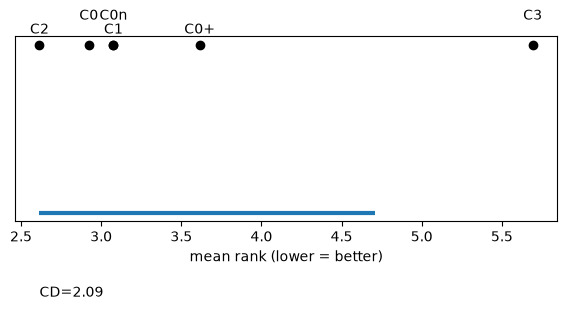


######## test_target | GATED | pool A, natural ########


,mean,sd_over_folds,mean_seed_sd_within_fold
C0,0.4717,0.1741,0.0278
C0+,0.4700,0.1808,0.0229
C0n,0.4723,0.1694,0.0299
C1,0.4721,0.1774,0.0253
C2,0.4764,0.1821,0.0227
C3,0.4082,0.1664,0.0187


,cond,vs,n_folds,mean_diff,ci_lo,ci_hi,dz,rank_biserial,folds_better,folds_worse,p_wilcoxon,p_holm
0,C0,C0+,13,0.0017,-0.0096,0.0117,0.0809,0.2527,8,5,0.4548,1.0000
1,C0n,C0+,13,0.0023,-0.0114,0.0152,0.0904,0.1648,8,5,0.6355,1.0000
2,C1,C0+,13,0.0021,-0.0046,0.0091,0.1594,-0.0110,5,8,1.0000,1.0000
3,C2,C0+,13,0.0064,-0.0028,0.0153,0.3687,0.3846,9,4,0.2439,0.9756
4,C3,C0+,13,-0.0618,-0.0832,-0.0387,-1.4312,-0.9341,1,12,0.0012,0.0061


,cond,vs,n_folds,mean_diff,ci_lo,ci_hi,dz,rank_biserial,folds_better,folds_worse,p_wilcoxon,p_holm
0,C0+,C0,13,-0.0017,-0.0117,0.0096,-0.0809,-0.2527,5,8,0.4548,1.0000
1,C0n,C0,13,0.0006,-0.0067,0.0096,0.0415,-0.1429,5,8,0.6848,1.0000
2,C1,C0,13,0.0004,-0.0063,0.0076,0.0314,-0.0330,5,8,0.9460,1.0000
3,C2,C0,13,0.0047,-0.0082,0.0152,0.2102,0.2527,6,7,0.4548,1.0000
4,C3,C0,13,-0.0635,-0.0858,-0.0423,-1.5263,-1.0000,0,13,0.0002,0.0012


Friedman chi2=27.55 p=0.0000 (N=13, k=6); Nemenyi CD=2.09; mean ranks (1=best):


...

,mean,sd_over_folds,mean_seed_sd_within_fold
C0,0.6938,0.1027,0.0183
C0+,0.6948,0.1061,0.0154
C0n,0.6972,0.1003,0.0187
C1,0.6964,0.1029,0.0161
C2,0.7011,0.1043,0.0149
C3,0.6392,0.1184,0.0180


,cond,vs,n_folds,mean_diff,ci_lo,ci_hi,dz,rank_biserial,folds_better,folds_worse,p_wilcoxon,p_holm
0,C0,C0+,14,-0.0010,-0.0068,0.0044,-0.0941,-0.0286,9,5,0.9515,1.0000
1,C0n,C0+,14,0.0024,-0.0049,0.0093,0.1699,0.2571,9,5,0.4263,1.0000
2,C1,C0+,14,0.0016,-0.0021,0.0056,0.2108,0.0667,7,7,0.8552,1.0000
3,C2,C0+,14,0.0064,0.0025,0.0101,0.8505,0.7524,11,3,0.0107,0.0430
4,C3,C0+,14,-0.0556,-0.0838,-0.0343,-1.0912,-1.0000,0,14,0.0001,0.0006


,cond,vs,n_folds,mean_diff,ci_lo,ci_hi,dz,rank_biserial,folds_better,folds_worse,p_wilcoxon,p_holm
0,C0+,C0,14,0.0010,-0.0044,0.0068,0.0941,0.0286,5,9,0.9515,1.0000
1,C0n,C0,14,0.0034,-0.0016,0.0090,0.3200,0.2190,6,8,0.5016,1.0000
2,C1,C0,14,0.0026,-0.0016,0.0069,0.3130,0.4286,8,6,0.1726,0.5178
3,C2,C0,14,0.0074,0.0030,0.0118,0.8534,0.6952,10,4,0.0203,0.0811
4,C3,C0,14,-0.0546,-0.0809,-0.0347,-1.1486,-1.0000,0,14,0.0001,0.0006


Friedman chi2=36.33 p=0.0000 (N=14, k=6); Nemenyi CD=2.02; mean ranks (1=best):


,C0,C0+,C0n,C1,C2,C3
rank,3.07,3.57,3.14,3.29,1.93,6.0


In [26]:
def holm(p):
    p = np.array(p, float); o = np.argsort(np.where(np.isnan(p), 2, p)); adj = np.full_like(p, np.nan); m = np.isfinite(p).sum(); run = 0
    for r, i in enumerate(o[:m]): run = max(run, (m - r) * p[i]); adj[i] = min(1, run)
    return adj

def boot_ci(d, n=10000, seed=0):
    rng = np.random.RandomState(seed); return np.percentile(d[rng.randint(0, len(d), (n, len(d)))].mean(1), [2.5, 97.5])

def paired_vs(wide, ref):
    rows = []
    for c in wide.columns:
        if c == ref: continue
        d = (wide[c] - wide[ref]).dropna().values
        if len(d) < 3: continue
        nz = d[d != 0]; p = stats.wilcoxon(nz).pvalue if len(nz) >= 5 else np.nan
        rk = stats.rankdata(np.abs(nz)); rbc = (rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum() if len(nz) else np.nan
        lo, hi = boot_ci(d); rows.append(dict(cond=c, vs=ref, n_folds=len(d), mean_diff=d.mean(), ci_lo=lo, ci_hi=hi, dz=d.mean() / (d.std(ddof=1) + 1e-12),
                                              rank_biserial=rbc, folds_better=int((d > 0).sum()), folds_worse=int((d < 0).sum()), p_wilcoxon=p))
    t = pd.DataFrame(rows); t["p_holm"] = holm(t["p_wilcoxon"].values) if len(t) else []; return t

def friedman_nemenyi(wide):
    w = wide.dropna(); k, N = w.shape[1], len(w)
    if N < 4 or k < 3: return None
    chi, p = stats.friedmanchisquare(*[w[c] for c in w]); ranks = w.rank(axis=1, ascending=False).mean()
    cd = stats.studentized_range.ppf(0.95, k, np.inf) / np.sqrt(2) * np.sqrt(k * (k + 1) / (6 * N)); return dict(chi2=chi, p=p, N=N, k=k, ranks=ranks, CD=cd)

def analyse(metric, **kw):
    w = select(metric=metric, **kw); fold = w.groupby(level="fold").mean(); sd_seed = w.groupby(level="fold").std().mean()
    summ = pd.DataFrame({"mean": fold.mean(), "sd_over_folds": fold.std(), "mean_seed_sd_within_fold": sd_seed}); return fold, summ

for metric in ("test_target", "test_macroNoOther"):
    for gated in (False, True):
        fold, summ = analyse(metric, gated=gated, c3_pool="A")
        print(f"\n######## {metric} | {'GATED' if gated else 'UNGATED (final round)'} | pool A, natural ########"); display(summ.round(4))
        t = paired_vs(fold, "C0+"); display(t.round(4)); t.to_csv(OUT / f"paired_vs_C0plus_{metric}_{'gated' if gated else 'ungated'}.csv", index=False)
        display(paired_vs(fold, "C0").round(4))
        fn = friedman_nemenyi(fold)
        if fn:
            print(f"Friedman chi2={fn['chi2']:.2f} p={fn['p']:.4f} (N={fn['N']}, k={fn['k']}); Nemenyi CD={fn['CD']:.2f}; mean ranks (1=best):"); display(fn["ranks"].round(2).to_frame("rank").T)
            if metric == "test_target" and not gated:
                fig, ax = plt.subplots(figsize=(7, 2.4)); r = fn["ranks"].sort_values(); ax.scatter(r.values, np.zeros(len(r)), c="k")
                for i, (n, v) in enumerate(r.items()): ax.annotate(n, (v, 0), (0, 8 + 10 * (i % 2)), textcoords="offset points", ha="center")
                ax.hlines(-0.3, r.min(), r.min() + fn["CD"], lw=3); ax.text(r.min(), -0.45, f"CD={fn['CD']:.2f}"); ax.set_yticks([]); ax.set_xlabel("mean rank (lower = better)")
                fig.savefig(OUT / "fig" / "cd_diagram_target.png", dpi=200, bbox_inches="tight"); plt.show()

## 12. Pool factor (U_A / U_B / U_AB), sampling, noise-augmentation

In [27]:
rows_pf = []
for pool in ("A", "B", "AB"):
    for samp in ("natural", "balanced"):
        if pool != "AB" and samp == "balanced": continue
        w = select(pools=(pool,), c3_pool=pool, sampling=samp)
        if w.empty: continue
        f = w.groupby(level="fold").mean()
        w = w.xs(0, level="seed"); f = w.groupby(level="fold").mean()
        for c in ("C1", "C2", "C3"):
            if c in f: rows_pf.append(dict(pool=pool, sampling=samp, cond=c, target_F1=f[c].mean(), delta_vs_C0plus=(f[c] - f["C0+"]).mean(), folds_better=int(((f[c] - f["C0+"]) > 0).sum()), n=f[c].notna().sum()))
pf_df = pd.DataFrame(rows_pf); display(pf_df.round(4)); pf_df.to_csv(OUT / "pool_factor_table.csv", index=False)
fold, _ = analyse("test_target"); 
if "C0n" in fold: display(paired_vs(fold[["C0", "C0n"]], "C0").round(4))

,pool,sampling,cond,target_F1,delta_vs_C0plus,folds_better,n
0,A,natural,C1,0.4795,0.0031,9,13
1,A,natural,C2,0.4857,0.0092,7,13
2,A,natural,C3,0.4069,-0.0695,1,13
3,B,natural,C1,0.4818,0.0054,8,13
4,B,natural,C2,0.4866,0.0101,8,13
5,B,natural,C3,0.3983,-0.0781,0,13
6,AB,natural,C1,0.4811,0.0046,7,13
7,AB,natural,C2,0.4834,0.0069,7,13
8,AB,natural,C3,0.3940,-0.0824,0,13
9,AB,balanced,C1,0.4777,0.0013,7,13


,cond,vs,n_folds,mean_diff,ci_lo,ci_hi,dz,rank_biserial,folds_better,folds_worse,p_wilcoxon,p_holm
0,C0n,C0,13,0.0006,-0.0067,0.0096,0.0415,-0.1429,5,8,0.6848,0.6848


## 13. Pseudo-label quality, calibration, logger-source diagnostics

In [28]:
if len(QD):
    for es in ("TEST", "VAL"):
        q = QD[(QD.eval_set == es) & (QD["round"] == 1)]; g = q.groupby(["cond", "pool", "sampling", "class"])[["n_true", "n_assigned", "n_correct"]].sum()
        g["precision"] = g.n_correct / g.n_assigned.where(g.n_assigned > 0); g["coverage"] = g.n_correct / g.n_true
        print(f"\nPseudo-label precision / coverage, round 1, {es} animals, pooled over folds+seeds ({'honest' if es=='TEST' else 'in-sample for calibration/radii'})")
        display(g.loc[(slice(None), "A", "natural"), :].round(3) if ("A", "natural") in set(zip(g.index.get_level_values(1), g.index.get_level_values(2))) else g.round(3))
        g.to_csv(OUT / f"pl_quality_{es}_round1.csv")
if len(CD):
    cal = CD.groupby(["pool"])[["T", "ece_before", "ece_after", "test_ece_raw", "test_ece_cal"]].mean(); print("\nCalibration (C1): temperature and ECE"); display(cal.round(4))
if len(SD):
    cols = ["cond", "pool", "sampling", "B_share_candidates", "B_share_selected"] + [f"Bshare_after_{t}" for t in TARGETS] + [f"Bshare_before_{t}" for t in TARGETS]
    src = SD[(SD["round"] == 1)][cols].groupby(["cond", "pool", "sampling"]).mean(); print("\nLogger-B share: candidates vs selected (under-representation = domain gap)"); display(src.round(3)); src.to_csv(OUT / "logger_source_share.csv")


Pseudo-label precision / coverage, round 1, TEST animals, pooled over folds+seeds (honest)


n_true  n_assigned  n_correct  precision  coverage
cond pool sampling class                                                           
C1   A    natural  ALL         32995200    21926325   20733937      0.946     0.628
                   Breathing    2672682     1671945    1582636      0.947     0.592
                   Feeding       832488      255064     226881      0.890     0.273
                   Gliding      1225476      431683     377058      0.873     0.308
                   Other         461670           0          0        NaN     0.000
                   Resting     16404558    12777593   12124422      0.949     0.739
                   Scratching    542334       11951       3259      0.273     0.006
                   Swimming    10855992     6778089    6419681      0.947     0.591
C2   A    natural  ALL         32995200    15914800   15604789      0.981     0.473
                   Breathing    2672682     1401250    1357332      0.969     0.508
                   Feeding       832488      208550     190106      0.912     0.228
                   Gliding      1225476      257900     240505      0.933     0.196
                   Other         461670           0          0        NaN     0.000
                   Resting     16404558     9702000    9566805      0.986     0.583
                   Scratching    542334       44900      27100      0.604     0.050
                   Swimming    10855992     4300200    4222941      0.982     0.389


Pseudo-label precision / coverage, round 1, VAL animals, pooled over folds+seeds (in-sample for calibration/radii)


n_true  n_assigned  n_correct  precision  coverage
cond pool sampling class                                                           
C1   A    natural  ALL         55214400    38848861   37459541      0.964     0.678
                   Breathing    4895532     3370195    3234936      0.960     0.661
                   Feeding      1451910      657625     597344      0.908     0.411
                   Gliding      1757364      622450     560239      0.900     0.319
                   Other         768078           0          0        NaN     0.000
                   Resting     26392176    22035004   21430449      0.973     0.812
                   Scratching   1337370       50376      45368      0.901     0.034
                   Swimming    18611970    12113211   11591205      0.957     0.623
C2   A    natural  ALL         55214400    29958000   29598986      0.988     0.536
                   Breathing    4895532     2755450    2701649      0.980     0.552
                   Feeding      1451910      471900     453490      0.961     0.312
                   Gliding      1757364      322750     299579      0.928     0.170
                   Other         768078           0          0        NaN     0.000
                   Resting     26392176    18646250   18502676      0.992     0.701
                   Scratching   1337370       50950      42741      0.839     0.032
                   Swimming    18611970     7710700    7598851      0.985     0.408


Calibration (C1): temperature and ECE


,T,ece_before,ece_after,test_ece_raw,test_ece_cal
pool,,,,,
A,1.4403,0.0809,0.0363,0.0838,0.0698
AB,1.3239,0.0561,0.0227,0.0569,0.0548
B,1.3264,0.0573,0.0236,0.0580,0.0552



Logger-B share: candidates vs selected (under-representation = domain gap)


B_share_candidates  B_share_selected  Bshare_after_Feeding  Bshare_after_Scratching  Bshare_after_Gliding  Bshare_before_Feeding  Bshare_before_Scratching  Bshare_before_Gliding
cond pool sampling                                                                                                                                                                                   
C1   A    natural                0.000             0.000                 0.000                    0.000                 0.000                  0.000                     0.000                  0.000
     AB   balanced               0.502             0.522                 0.589                    0.593                 0.509                  0.581                     0.581                  0.508
          natural                0.898             0.903                 0.925                    0.918                 0.892                  0.924                     0.916                  0.892
     B    natural                1.000             1.000                 1.000                    1.000                 1.000                  1.000                     1.000                  1.000
C2   A    natural                0.000             0.000                 0.000                    0.000                 0.000                  0.000                     0.000                  0.000
     AB   balanced               0.502             0.456                 0.582                    0.459                 0.431                  0.583                     0.458                  0.432
          natural                0.898             0.873                 0.917                    0.857                 0.813                  0.917                     0.857                  0.813
     B    natural                1.000             1.000                 1.000                    1.000                 1.000                  1.000                     1.000                  1.000

# Visuals

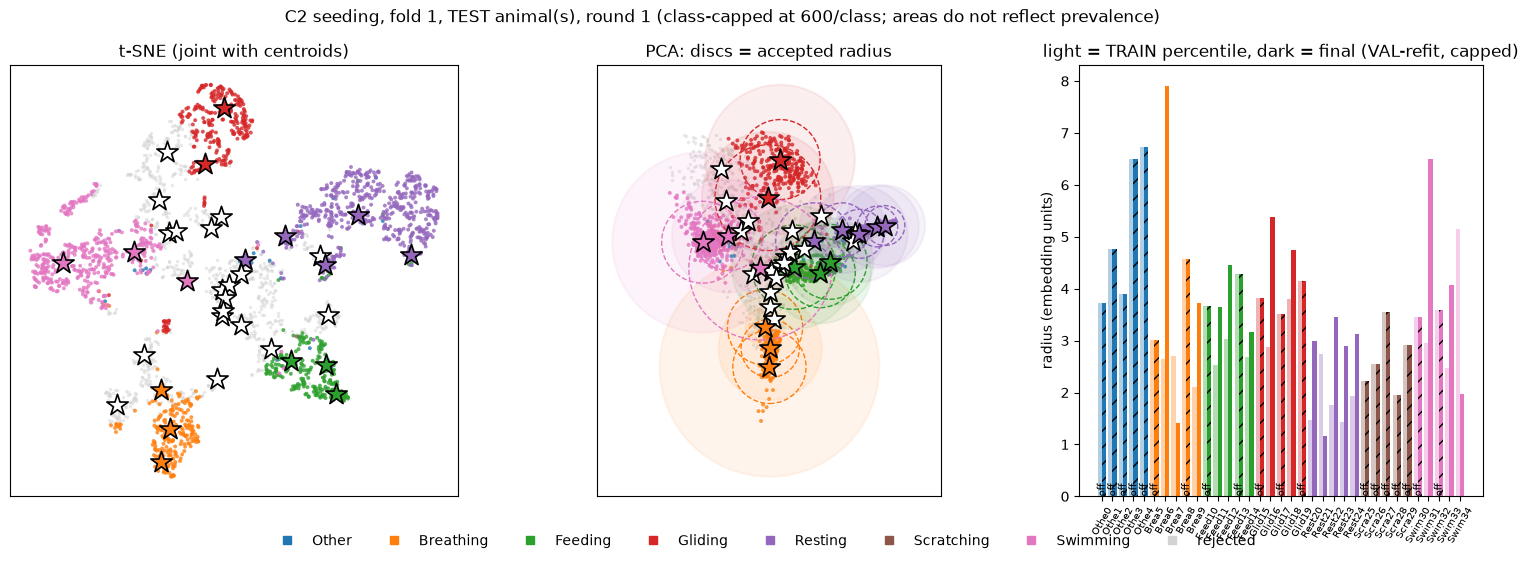

,cls,n_true,accepted,precision,coverage
0,Other,137,0,NaN,0.000
1,Breathing,426,231,0.983,0.533
2,Feeding,416,235,0.906,0.512
3,Gliding,498,303,0.914,0.556
4,Resting,2872,2622,0.983,0.897
5,Scratching,26,0,NaN,0.000
6,Swimming,2537,1752,0.992,0.685


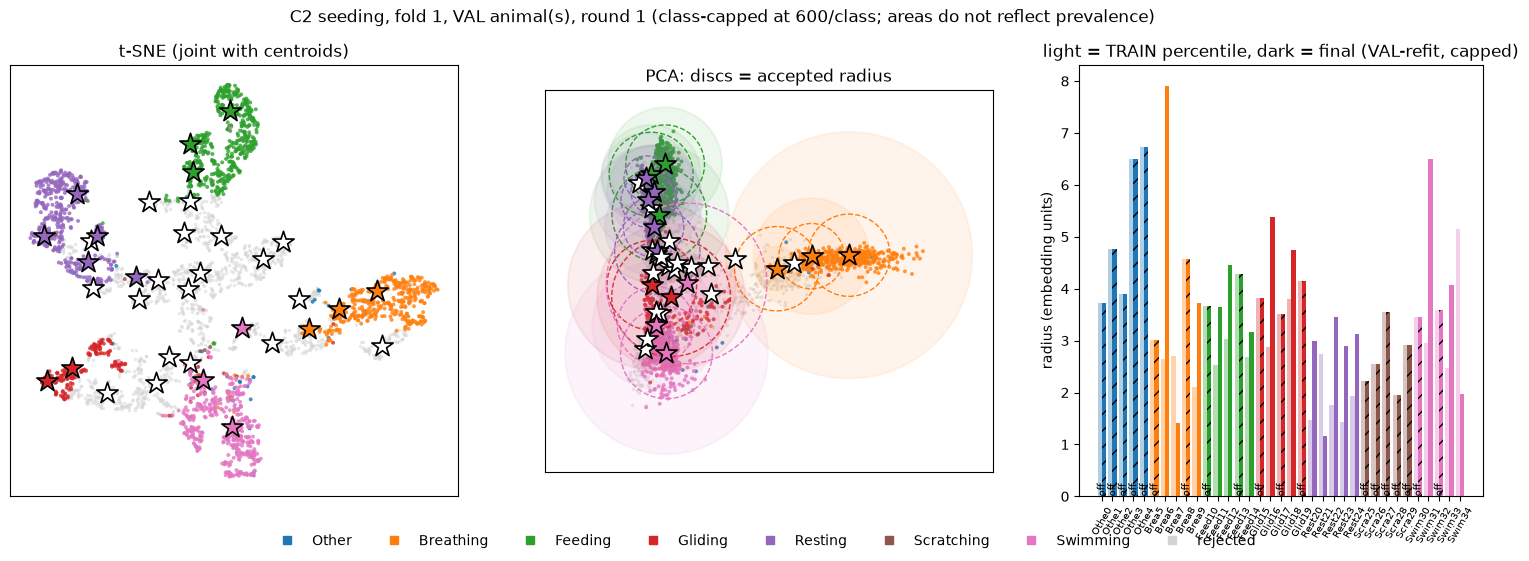

,cls,n_true,accepted,precision,coverage
0,Other,227,0,NaN,0.000
1,Breathing,1047,694,0.980,0.649
2,Feeding,663,517,0.986,0.769
3,Gliding,502,178,0.927,0.329
4,Resting,7138,5374,0.996,0.750
5,Scratching,435,0,NaN,0.000
6,Swimming,4159,3169,0.980,0.747


In [29]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from matplotlib.patches import Circle
from matplotlib.lines import Line2D

def plot_seeding(fi=0, seed=0, frac=1.0, eval_set="TEST", cap=600):
    """C2 seeding visual for one fold (round 1): centroids, accepted radii, accepted vs rejected sub-windows."""
    sp = split_fold(fi, INDIVIDUALS[fi])
    st = pickle.load(open(OUT / "units" / f"f{fi+1:02d}_s{seed}_fr{frac}.pkl", "rb"))
    base = new_model(); base.load_state_dict(st["base_state"]); base.eval()
    sd = fit_seeds(base, subset_train(sp["train_inds"], frac, seed, fi), sp["val"], SEED + fi * 100 + 1)
    E = cut_labelled(sp["test"] if eval_set == "TEST" else sp["val"])
    Z, (y, u) = embed(base, E["X"]), sub_majority(E["Y"]); Z, y = Z[u], y[u]
    near, dist = nearest(Z, sd["centers"]); acc = sd["active"][near] & (dist <= sd["radius"][near])
    rng = np.random.RandomState(0)
    keep = np.concatenate([rng.permutation(np.flatnonzero(y == c))[:cap] for c in range(NC)])
    Zs, ys, accs, n = Z[keep], y[keep], acc[keep], len(keep)
    cols = plt.cm.tab10(np.arange(NC)); cen_c = cols[sd["cls"]]
    J = np.vstack([Zs, sd["centers"]])
    T2 = TSNE(2, perplexity=min(30, (len(J) - 1) / 3), init="pca", random_state=0).fit_transform(J)
    pca = PCA(2).fit(Zs); Pp, Pc = pca.transform(Zs), pca.transform(sd["centers"])

    fig, ax = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw=dict(width_ratios=[1, 1, .9]))
    for a, XY, CC, ttl in ((ax[0], T2[:n], T2[n:], "t-SNE (joint with centroids)"), (ax[1], Pp, Pc, "PCA: discs = accepted radius")):
        a.scatter(*XY[~accs].T, s=6, c="lightgrey", alpha=.5, lw=0)
        a.scatter(*XY[accs].T, s=8, c=cols[ys[accs]], alpha=.8, lw=0)
        for j, (x_, y_) in enumerate(CC):
            a.scatter(x_, y_, marker="*", s=260, facecolor=cen_c[j] if sd["active"][j] else "white", edgecolor="k", lw=1.2, zorder=5)
        a.set_title(ttl); a.set_xticks([]); a.set_yticks([])
    a = ax[1]
    for j in np.flatnonzero(sd["active"]):
        a.add_patch(Circle(Pc[j], sd["radius"][j], fc=cen_c[j], alpha=.08, ec=cen_c[j], lw=1.5))
        a.add_patch(Circle(Pc[j], sd["train_radius"][j], fill=False, ec=cen_c[j], ls="--", lw=1))
    a.set_aspect("equal"); a.autoscale_view()
    a = ax[2]; j = np.arange(len(sd["radius"]))
    a.bar(j - .2, sd["train_radius"], .4, color=cen_c, alpha=.35); bars = a.bar(j + .2, sd["radius"], .4, color=cen_c)
    for k in np.flatnonzero(~sd["active"]): bars[k].set_hatch("//"); a.text(k, 0, "off", ha="center", va="bottom", fontsize=7, rotation=90)
    a.set_xticks(j); a.set_xticklabels([f"{CLASS_NAMES[c][:4]}{k}" for k, c in enumerate(sd["cls"])], rotation=60, fontsize=7)
    a.set_ylabel("radius (embedding units)"); a.set_title("light = TRAIN percentile, dark = final (VAL-refit, capped)")
    fig.legend([Line2D([], [], marker="s", ls="", color=cols[c]) for c in range(NC)] + [Line2D([], [], marker="s", ls="", color="lightgrey")],
               CLASS_NAMES + ["rejected"], loc="lower center", ncol=NC + 1, frameon=False)
    fig.suptitle(f"C2 seeding, fold {fi+1}, {eval_set} animal(s), round 1 (class-capped at {cap}/class; areas do not reflect prevalence)")
    fig.savefig(OUT / "fig" / f"seeding_fold{fi+1}_{eval_set}.png", dpi=200, bbox_inches="tight"); plt.show()

    rows = []
    for c in range(NC):
        m = acc & (sd["cls"][near] == c); nt = int((y == c).sum())
        rows.append(dict(cls=CLASS_NAMES[c], n_true=nt, accepted=int(m.sum()), precision=float((y[m] == c).mean()) if m.any() else np.nan,
                         coverage=float((m & (y == c)).sum() / max(1, nt))))
    display(pd.DataFrame(rows).round(3))

plot_seeding(0, 0, eval_set="TEST")
plot_seeding(0, 0, eval_set="VAL")

## 14. Label-efficiency and unlabelled-data scaling curves

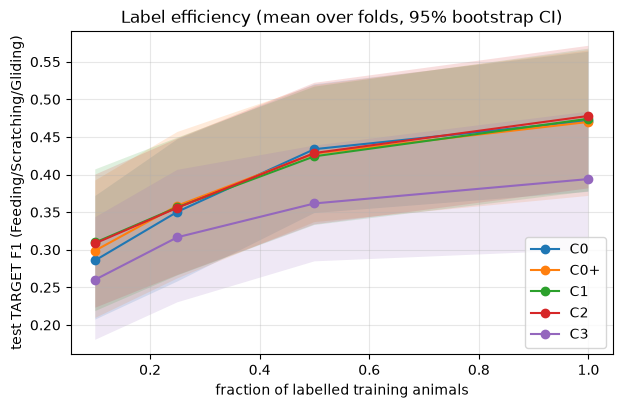

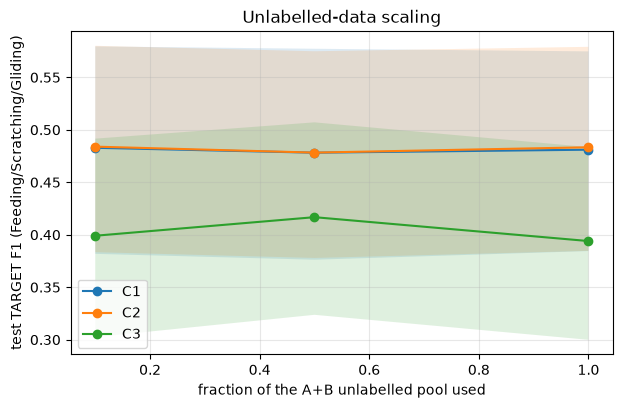

In [30]:
def curve(df_fold_by_x, conds, xlabel, title, fn):
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for c in conds:
        xs, ms, lo, hi = [], [], [], []
        for x, f in df_fold_by_x.items():
            if c in f and f[c].notna().sum() >= 3:
                v = f[c].dropna().values; l, h = boot_ci(v); xs.append(x); ms.append(v.mean()); lo.append(l); hi.append(h)
        if xs: ax.plot(xs, ms, "o-", label=c); ax.fill_between(xs, lo, hi, alpha=0.15)
    ax.set_xlabel(xlabel); ax.set_ylabel("test TARGET F1 (Feeding/Scratching/Gliding)"); ax.set_title(title); ax.legend(); ax.grid(alpha=.3)
    fig.savefig(OUT / "fig" / fn, dpi=200, bbox_inches="tight"); plt.show()

le = {fr: select(frac=fr, pools=("A",), c3_pool="AB").groupby(level="fold").mean() for fr in sorted(RES.frac.unique())}
curve(le, ["C0", "C0+", "C1", "C2", "C3"], "fraction of labelled training animals", "Label efficiency (mean over folds, 95% bootstrap CI)", "label_efficiency.png")
pd.concat({fr: f.mean() for fr, f in le.items()}, axis=1).round(4).to_csv(OUT / "label_efficiency_table.csv")
sc = {}
for pf in [*SC_FRACS, 1.0]:
    d = RES[(RES.frac == 1.0) & (RES.pool == "AB") & (RES.sampling == "natural") & (RES.pool_frac == pf)]
    cols = {}
    for c in ("C1", "C2"):
        x = d[(d.cond == c) & (d.kind == "pseudo") & (d["round"] == FINAL)]
        if len(x): cols[c] = x.set_index(["fold", "seed"])["test_target"]
    x = d[d.kind == "c3"]
    if len(x): cols["C3"] = x.set_index(["fold", "seed"])["test_target"]
    if cols: sc[pf] = pd.DataFrame(cols).groupby(level="fold").mean()
curve(sc, ["C1", "C2", "C3"], "fraction of the A+B unlabelled pool used", "Unlabelled-data scaling", "unlabelled_scaling.png")

## 15. Per-class F1 and confusion matrices

,C0,C0+,C0n,C1,C2,C3
Other,0.002,0.004,0.002,0.002,0.002,0.000
Breathing,0.858,0.862,0.861,0.863,0.868,0.804
Feeding,0.520,0.518,0.518,0.524,0.535,0.400
Gliding,0.608,0.606,0.612,0.607,0.613,0.585
Resting,0.922,0.920,0.926,0.922,0.922,0.889
Scratching,0.293,0.297,0.296,0.299,0.298,0.253
Swimming,0.873,0.873,0.876,0.877,0.877,0.824


,C0,C0+,C0n,C1,C2,C3
Other,0.006,0.011,0.007,0.005,0.006,0.001
Breathing,0.158,0.143,0.143,0.143,0.137,0.200
Feeding,0.273,0.299,0.263,0.286,0.289,0.247
Gliding,0.184,0.188,0.183,0.180,0.179,0.219
Resting,0.106,0.111,0.101,0.108,0.112,0.138
Scratching,0.220,0.215,0.229,0.219,0.218,0.182
Swimming,0.046,0.047,0.044,0.046,0.045,0.094


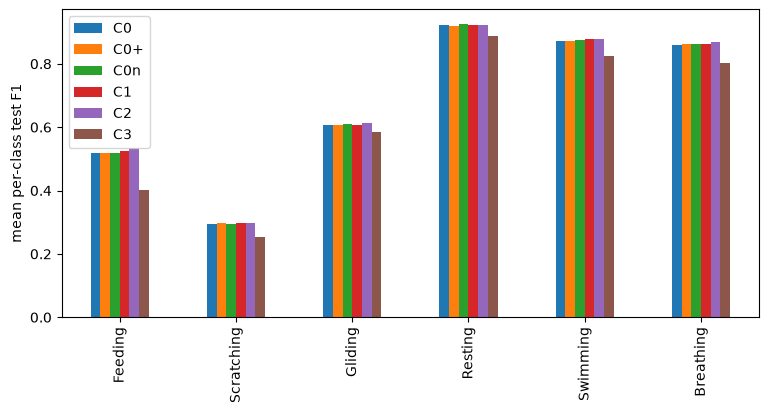

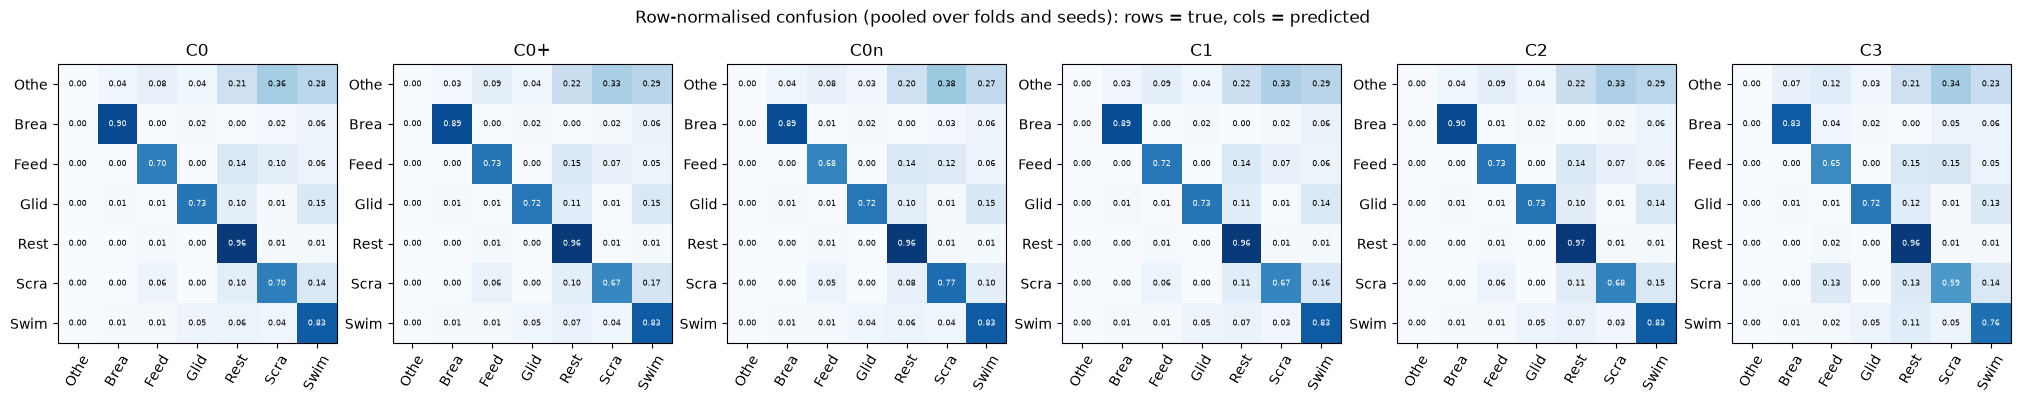

In [31]:
def per_class_table(gated=False):
    d = RES[RES.frac == 1.0]; sets = {"C0": d[d.kind == "baseline"], "C0+": d[(d.kind == "ctrl") & (d["round"] == FINAL)], "C0n": d[d.kind == "noise"],
        "C1": d[(d.cond == "C1") & (d.kind == ("gated" if gated else "pseudo")) & (d.pool == "A") & (d.pool_frac == 1.0) & ((d["round"] == FINAL) | gated)],
        "C2": d[(d.cond == "C2") & (d.kind == ("gated" if gated else "pseudo")) & (d.pool == "A") & (d.pool_frac == 1.0) & ((d["round"] == FINAL) | gated)],
        "C3": d[(d.kind == "c3") & (d.pool == "A") & (d.pool_frac == 1.0)]}
    return {k: v for k, v in sets.items() if len(v)}
sets = per_class_table()
pc = pd.DataFrame({k: v.groupby("fold")[[f"test_F1_{n}" for n in CLASS_NAMES]].mean().mean() for k, v in sets.items()}); pc.index = CLASS_NAMES
pcs = pd.DataFrame({k: v.groupby("fold")[[f"test_F1_{n}" for n in CLASS_NAMES]].mean().std() for k, v in sets.items()}); pcs.index = CLASS_NAMES
display(pc.round(3)); display(pcs.round(3)); pc.to_csv(OUT / "per_class_F1_mean.csv")
pc.loc[TARGETS + ["Resting", "Swimming", "Breathing"]].plot.bar(figsize=(9, 4), ylabel="mean per-class test F1"); plt.savefig(OUT / "fig" / "per_class_F1.png", dpi=200, bbox_inches="tight"); plt.show()
fig, axs = plt.subplots(1, len(sets), figsize=(4.2 * len(sets), 4))
for ax, (k, v) in zip(np.atleast_1d(axs), sets.items()):
    cm = np.sum([c for c in v["cm"]], axis=0).astype(float); cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    ax.imshow(cm, vmin=0, vmax=1, cmap="Blues"); ax.set_title(k); ax.set_xticks(range(NC)); ax.set_yticks(range(NC))
    ax.set_xticklabels([n[:4] for n in CLASS_NAMES], rotation=60); ax.set_yticklabels([n[:4] for n in CLASS_NAMES])
    for i in range(NC):
        for j in range(NC): ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center", fontsize=6, color="w" if cm[i, j] > .5 else "k")
fig.suptitle("Row-normalised confusion (pooled over folds and seeds): rows = true, cols = predicted"); fig.savefig(OUT / "fig" / "confusion_matrices.png", dpi=200, bbox_inches="tight"); plt.show()

## 16. Seed variance vs effect size, and gated vs ungated

In [32]:
w = select(metric="test_target"); seed_sd = w.groupby(level="fold").std().mean(); fold_means = w.groupby(level="fold").mean()
print("Baseline (C0) seed SD within fold vs the effects being claimed:")
print(pd.DataFrame({"mean seed SD within fold": seed_sd, "mean effect vs C0+ (folds)": fold_means.sub(fold_means["C0+"], axis=0).mean()}).round(4))
_cols = ["C1", "C2"]
_m = lambda g: select(gated=g, metric="test_target").reindex(columns=_cols).mean()
gu = pd.DataFrame({"ungated": _m(False), "gated": _m(True)})
display(gu.round(4)); gu.to_csv(OUT / "gated_vs_ungated.csv")
print("Report ungated as primary; the gate picks the round on only 2 validation animals.")
print("All tables/figures saved in", OUT)

Baseline (C0) seed SD within fold vs the effects being claimed:
     mean seed SD within fold  mean effect vs C0+ (folds)
C0                     0.0278                      0.0017
C0+                    0.0229                      0.0000
C0n                    0.0299                      0.0023
C1                     0.0249                      0.0042
C2                     0.0245                      0.0079
C3                     0.0187                     -0.0618


,ungated,gated
C1,0.4742,0.4721
C2,0.4779,0.4764


Report ungated as primary; the gate picks the round on only 2 validation animals.
All tables/figures saved in Model_results/FINAL_2026_10_11_final


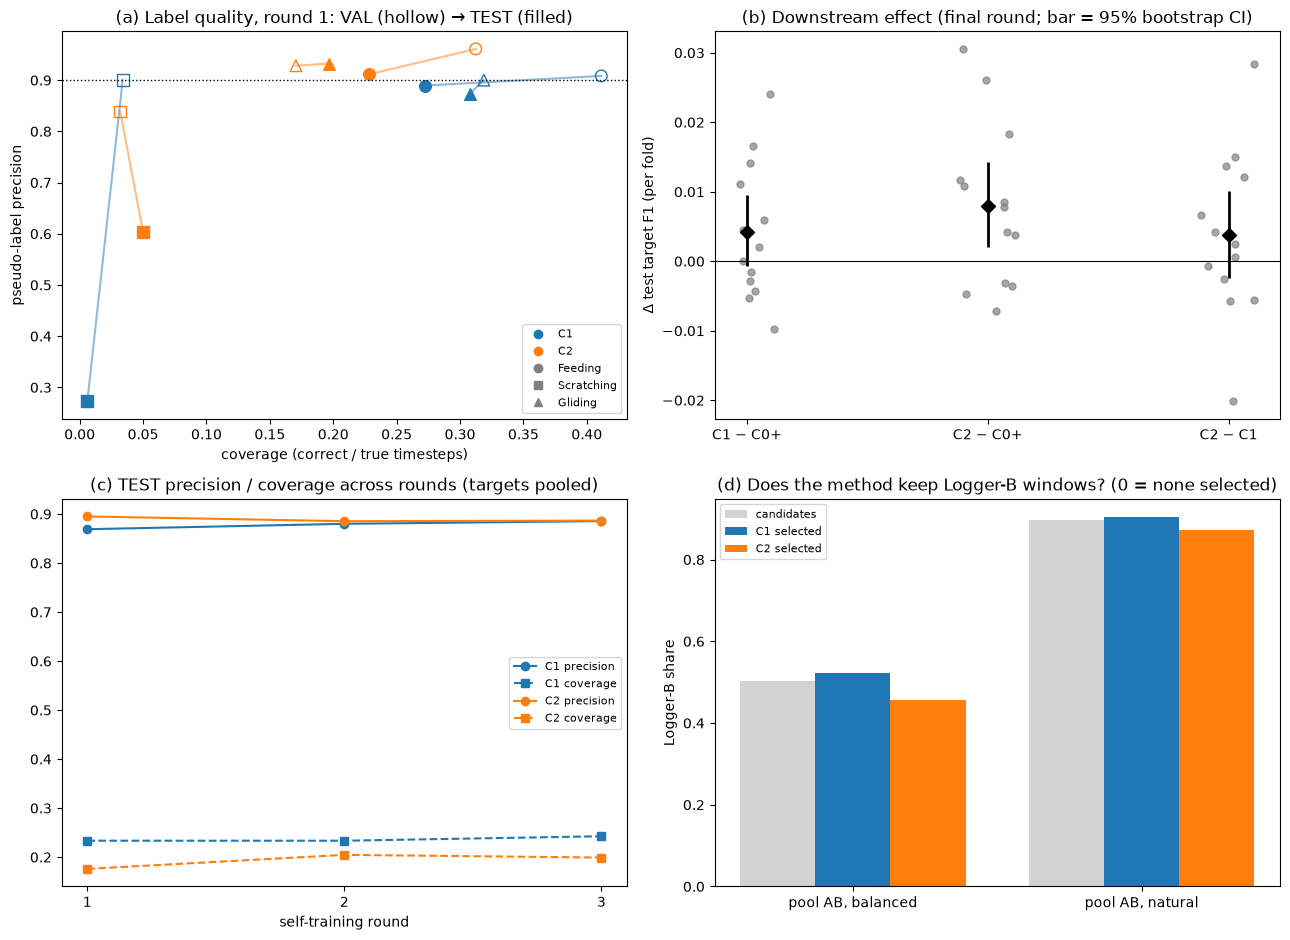

{'C1': '42/42 fold-seeds completed all 3 rounds', 'C2': '42/42 fold-seeds completed all 3 rounds'}


In [33]:
from matplotlib.lines import Line2D

def plot_method_defence(pool="A", sampling="natural"):
    """C1 (probability threshold) vs C2 (centroid seeding): label quality, downstream effect, stability over rounds, logger-B robustness."""
    col = {"C1": "tab:blue", "C2": "tab:orange"}; mk = dict(zip(TARGETS, "os^"))
    fig, ax = plt.subplots(2, 2, figsize=(13, 9.5))
    # (a) precision vs coverage, VAL (hollow, in-sample for thresholds/radii) -> TEST (filled, honest)
    q = QD[(QD["round"] == 1) & (QD.pool == pool) & (QD.sampling == sampling) & QD["class"].isin(TARGETS)]
    g = q.groupby(["cond", "eval_set", "class"])[["n_true", "n_assigned", "n_correct"]].sum()
    g["prec"] = g.n_correct / g.n_assigned.where(g.n_assigned > 0); g["cover"] = g.n_correct / g.n_true
    a = ax[0, 0]
    for c in ("C1", "C2"):
        for t in TARGETS:
            try: v, te = g.loc[(c, "VAL", t)], g.loc[(c, "TEST", t)]
            except KeyError: continue
            a.plot([v["cover"], te["cover"]], [v["prec"], te["prec"]], "-", color=col[c], alpha=.5)
            a.scatter(v["cover"], v["prec"], marker=mk[t], facecolor="none", edgecolor=col[c], s=70)
            a.scatter(te["cover"], te["prec"], marker=mk[t], color=col[c], s=70)
    a.axhline(.9, ls=":", c="k", lw=1); a.set_xlabel("coverage (correct / true timesteps)"); a.set_ylabel("pseudo-label precision")
    a.set_title("(a) Label quality, round 1: VAL (hollow) → TEST (filled)")
    a.legend([Line2D([], [], color=col[c], marker="o", ls="") for c in col] + [Line2D([], [], color="grey", marker=mk[t], ls="") for t in TARGETS],
             [*col, *TARGETS], fontsize=8, loc="best")
    # (b) downstream effect, paired by fold
    f = select(metric="test_target", pools=(pool,), sampling=sampling).groupby(level="fold").mean(); diffs = {}
    for lab, (x_, y_) in {"C1 − C0+": ("C1", "C0+"), "C2 − C0+": ("C2", "C0+"), "C2 − C1": ("C2", "C1")}.items():
        if x_ in f and y_ in f: diffs[lab] = (f[x_] - f[y_]).dropna().values
    a, rng = ax[0, 1], np.random.RandomState(0)
    for i, d in enumerate(diffs.values()):
        a.scatter(i + rng.uniform(-.12, .12, len(d)), d, c="grey", s=25, alpha=.7); a.scatter(i, d.mean(), c="k", marker="D", s=50)
        if len(d) >= 3: lo, hi = boot_ci(d); a.vlines(i, lo, hi, color="k", lw=2)
    a.axhline(0, c="k", lw=.8); a.set_xticks(range(len(diffs))); a.set_xticklabels(list(diffs)); a.set_ylabel("Δ test target F1 (per fold)")
    a.set_title("(b) Downstream effect (final round; bar = 95% bootstrap CI)")
    # (c) stability over self-training rounds, TEST animals, target classes pooled
    q = QD[(QD.eval_set == "TEST") & (QD.pool == pool) & (QD.sampling == sampling) & QD["class"].isin(TARGETS)]
    g = q.groupby(["cond", "round"])[["n_true", "n_assigned", "n_correct"]].sum(); a = ax[1, 0]
    for c in ("C1", "C2"):
        if c not in g.index.get_level_values(0): continue
        h = g.loc[c]
        a.plot(h.index, h.n_correct / h.n_assigned.where(h.n_assigned > 0), "o-", color=col[c], label=f"{c} precision")
        a.plot(h.index, h.n_correct / h.n_true, "s--", color=col[c], label=f"{c} coverage")
    a.set_xticks(sorted(QD["round"].unique())); a.set_xlabel("self-training round"); a.legend(fontsize=8); a.set_title("(c) TEST precision / coverage across rounds (targets pooled)")
    # (d) logger-B robustness: share of Logger B among candidates vs among selected windows
    s = SD[(SD["round"] == 1) & (SD.pool == "AB")].groupby(["sampling", "cond"])[["B_share_candidates", "B_share_selected"]].mean(); a = ax[1, 1]
    samps = list(s.index.get_level_values(0).unique()); x = np.arange(len(samps)); wd = .26
    a.bar(x - wd, [s.loc[sm]["B_share_candidates"].mean() for sm in samps], wd, color="lightgrey", label="candidates")
    for k, c in enumerate(("C1", "C2")):
        a.bar(x + k * wd, np.nan_to_num([s["B_share_selected"].get((sm, c), np.nan) for sm in samps]), wd, color=col[c], label=f"{c} selected")
    a.set_xticks(x); a.set_xticklabels([f"pool AB, {sm}" for sm in samps]); a.set_ylabel("Logger-B share"); a.legend(fontsize=8)
    a.set_title("(d) Does the method keep Logger-B windows? (0 = none selected)")
    fig.tight_layout(); fig.savefig(OUT / "fig" / "method_defence_C1_vs_C2.png", dpi=200, bbox_inches="tight"); plt.show()
    d = RES[(RES.frac == 1.0) & (RES.kind == "pseudo") & (RES.pool == pool) & (RES.sampling == sampling) & (RES.pool_frac == 1.0) & (RES["round"] == FINAL)]
    tot = len(RES[(RES.kind == "baseline") & (RES.frac == 1.0)])
    print({c: f"{len(d[d.cond == c])}/{tot} fold-seeds completed all {FINAL} rounds" for c in ("C1", "C2")})

plot_method_defence()

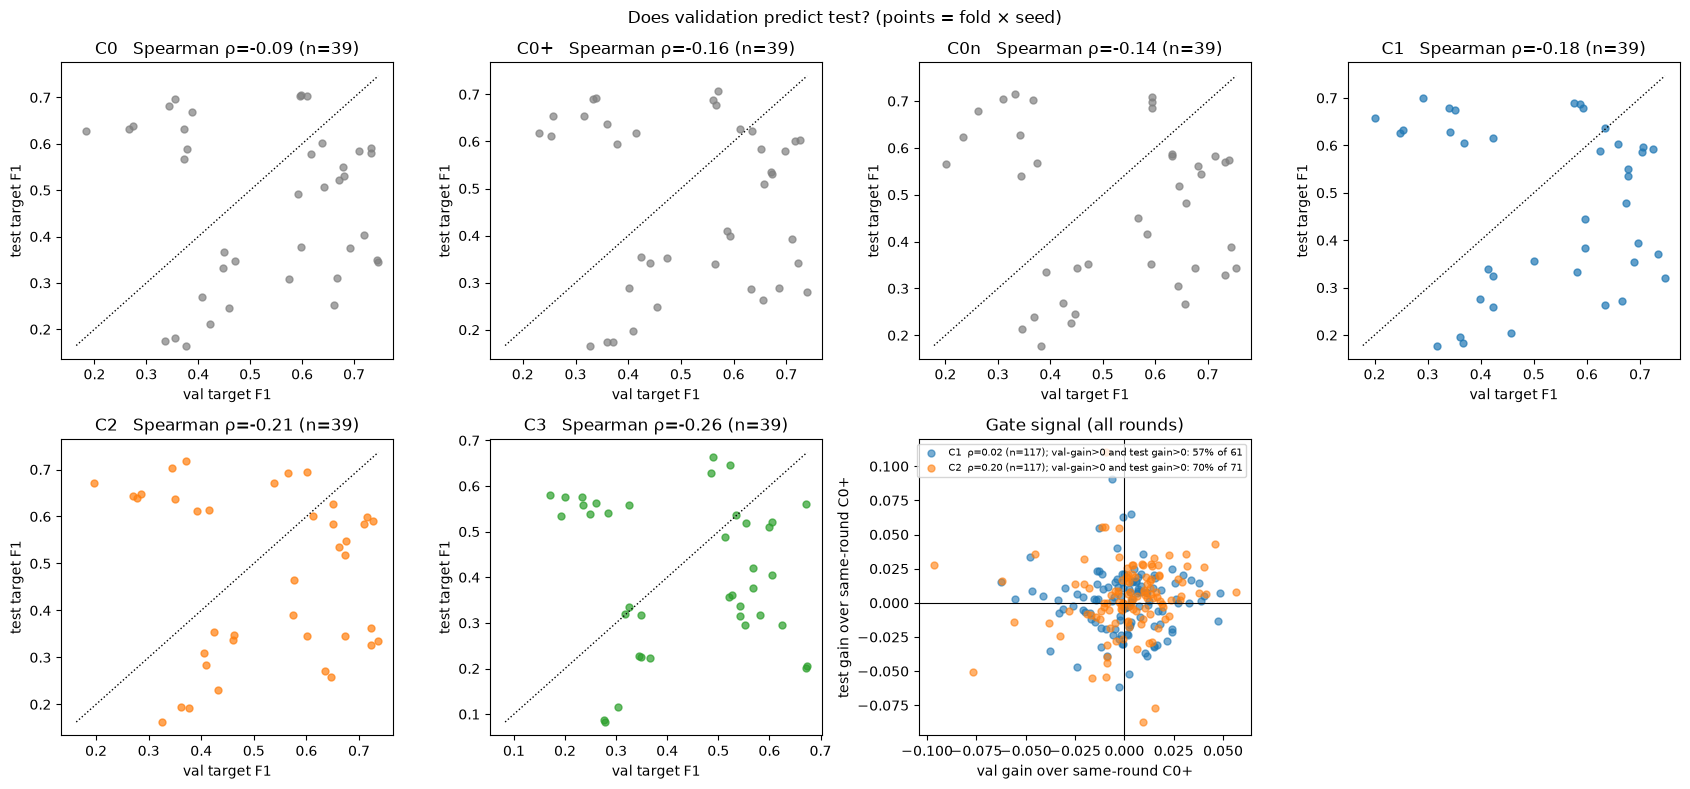

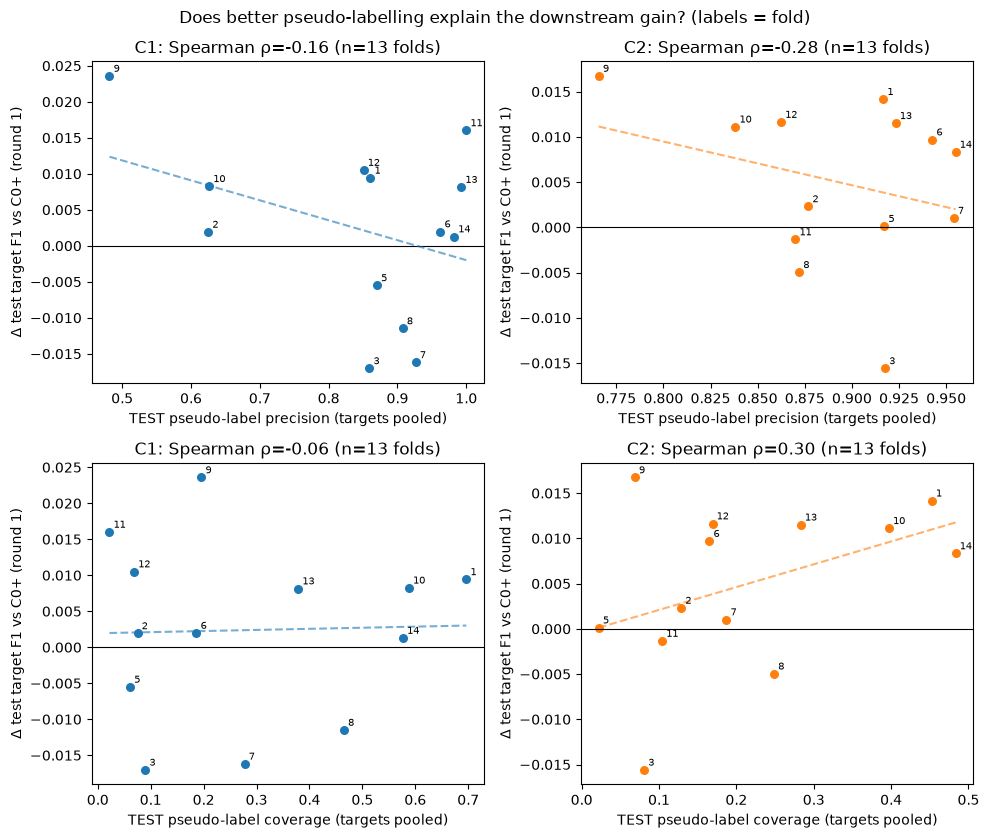

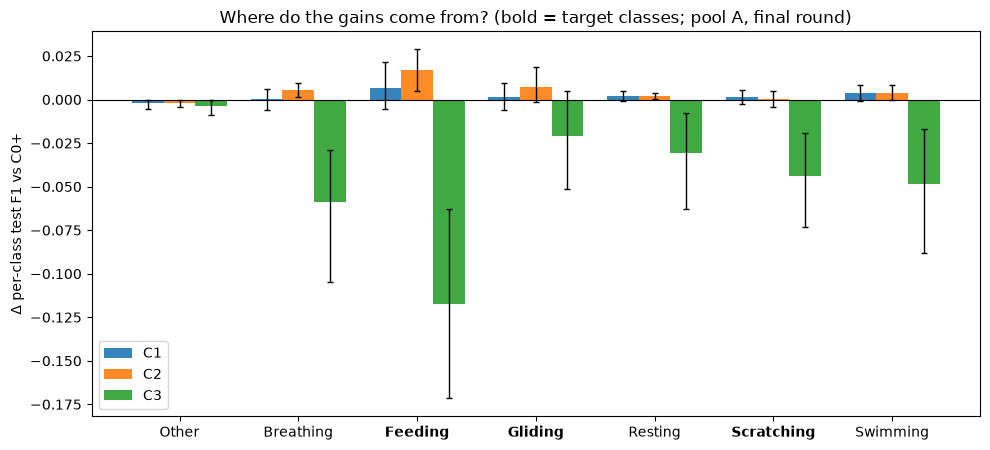

In [34]:
def _rho(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float); m = np.isfinite(x) & np.isfinite(y)
    return (stats.spearmanr(x[m], y[m])[0] if m.sum() >= 4 else np.nan), int(m.sum())

COL = {"C1": "tab:blue", "C2": "tab:orange", "C3": "tab:green"}

def plot_val_vs_test(pool="A", sampling="natural"):
    """Does the 2-animal validation score predict test? Evidence for reporting ungated results as primary."""
    v = select(metric="val_target", pools=(pool,), sampling=sampling, c3_pool=pool)
    t = select(metric="test_target", pools=(pool,), sampling=sampling, c3_pool=pool)
    fig, axs = plt.subplots(2, 4, figsize=(17, 8)); axs = axs.ravel()
    for a, c in zip(axs, ("C0", "C0+", "C0n", "C1", "C2", "C3")):
        a.set_xlabel("val target F1"); a.set_ylabel("test target F1")
        if c not in v or c not in t: a.set_title(f"{c}: no data"); continue
        d = pd.concat([v[c], t[c]], axis=1, keys=["val", "test"]).dropna(); rho, n = _rho(d.val, d.test)
        a.scatter(d.val, d.test, s=25, alpha=.7, color=COL.get(c, "grey")); lo, hi = d.values.min(), d.values.max()
        a.plot([lo, hi], [lo, hi], "k:", lw=1); a.set_title(f"{c}   Spearman ρ={rho:.2f} (n={n})")
    a = axs[6]; p = RES[(RES.kind == "pseudo") & (RES.frac == 1.0) & (RES.pool == pool) & (RES.sampling == sampling) & (RES.pool_frac == 1.0)]
    k = RES[(RES.kind == "ctrl") & (RES.frac == 1.0)][["fold", "seed", "round", "val_target", "test_target"]]
    m = p.merge(k, on=["fold", "seed", "round"], suffixes=("", "_ctrl"))
    m["val_gain"], m["test_gain"] = m.val_target - m.val_target_ctrl, m.test_target - m.test_target_ctrl
    for c in ("C1", "C2"):
        d = m[m.cond == c][["val_gain", "test_gain"]].dropna(); rho, n = _rho(d.val_gain, d.test_gain); ps = d[d.val_gain > 0]
        hit = f"{(ps.test_gain > 0).mean():.0%} of {len(ps)}" if len(ps) else "none pass"
        a.scatter(d.val_gain, d.test_gain, s=25, alpha=.6, color=COL[c], label=f"{c}  ρ={rho:.2f} (n={n}); val-gain>0 and test gain>0: {hit}")
    a.axhline(0, c="k", lw=.8); a.axvline(0, c="k", lw=.8); a.set_xlabel("val gain over same-round C0+"); a.set_ylabel("test gain over same-round C0+")
    a.set_title("Gate signal (all rounds)"); a.legend(fontsize=7, loc="best"); axs[7].axis("off")
    fig.suptitle("Does validation predict test? (points = fold × seed)"); fig.tight_layout()
    fig.savefig(OUT / "fig" / "val_vs_test.png", dpi=200, bbox_inches="tight"); plt.show()

def plot_quality_vs_gain(rnd=1, pool="A", sampling="natural"):
    """Mechanism check: does better pseudo-label precision / coverage on the TEST animal go with a larger downstream gain (per fold)?"""
    q = QD[(QD.eval_set == "TEST") & (QD["round"] == rnd) & (QD.frac == 1.0) & (QD.pool == pool) & (QD.sampling == sampling)
           & (QD.pool_frac == 1.0) & QD["class"].isin(TARGETS)].groupby(["cond", "fold", "seed"])[["n_true", "n_assigned", "n_correct"]].sum()
    q["precision"] = q.n_correct / q.n_assigned.where(q.n_assigned > 0); q["coverage"] = q.n_correct / q.n_true
    q = q.groupby(["cond", "fold"])[["precision", "coverage"]].mean()
    ctrl = RES[(RES.kind == "ctrl") & (RES.frac == 1.0) & (RES["round"] == rnd)].set_index(["fold", "seed"]).test_target
    fig, axs = plt.subplots(2, 2, figsize=(10, 8.5))
    for j, c in enumerate(("C1", "C2")):
        s = RES[(RES.kind == "pseudo") & (RES.cond == c) & (RES.frac == 1.0) & (RES.pool == pool) & (RES.sampling == sampling)
                & (RES.pool_frac == 1.0) & (RES["round"] == rnd)].set_index(["fold", "seed"]).test_target
        gain = (s - ctrl).dropna().groupby(level="fold").mean()
        for i, mname in enumerate(("precision", "coverage")):
            a = axs[i, j]; a.axhline(0, c="k", lw=.8); a.set_xlabel(f"TEST pseudo-label {mname} (targets pooled)"); a.set_ylabel(f"Δ test target F1 vs C0+ (round {rnd})")
            if c not in q.index.get_level_values(0) or not len(gain): a.set_title(f"{c}: no data"); continue
            d = pd.concat([q.loc[c][mname], gain], axis=1, keys=["x", "gain"]).dropna(); rho, n = _rho(d.x, d.gain)
            a.scatter(d.x, d.gain, s=30, color=COL[c])
            for fo, r_ in d.iterrows(): a.annotate(str(fo), (r_.x, r_.gain), fontsize=7, xytext=(3, 3), textcoords="offset points")
            if n >= 4 and d.x.std() > 0: b = np.polyfit(d.x, d.gain, 1); xs = np.linspace(d.x.min(), d.x.max(), 20); a.plot(xs, np.polyval(b, xs), "--", color=COL[c], alpha=.6)
            a.set_title(f"{c}: Spearman ρ={rho:.2f} (n={n} folds)")
    fig.suptitle("Does better pseudo-labelling explain the downstream gain? (labels = fold)"); fig.tight_layout()
    fig.savefig(OUT / "fig" / f"quality_vs_gain_round{rnd}.png", dpi=200, bbox_inches="tight"); plt.show()

def plot_per_class_gain():
    """Per-class test F1 gain over the C0+ control (mean over folds, 95% bootstrap CI of paired fold differences)."""
    cols = [f"test_F1_{n}" for n in CLASS_NAMES]; sets = per_class_table()
    if "C0+" not in sets: print("no C0+ rows yet"); return
    fl = {k: v.groupby("fold")[cols].mean() for k, v in sets.items()}; conds = [c for c in ("C1", "C2", "C3") if c in fl]
    fig, ax = plt.subplots(figsize=(10, 4.6)); wd = .8 / max(1, len(conds)); x = np.arange(NC)
    for i, c in enumerate(conds):
        diff = (fl[c] - fl["C0+"]).reindex(columns=cols); mu, lo, hi = [], [], []
        for cl in cols:
            d = diff[cl].dropna().values; mu.append(d.mean() if len(d) else np.nan)
            l, h = boot_ci(d) if len(d) >= 3 else (np.nan, np.nan); lo.append(l); hi.append(h)
        mu, lo, hi = map(np.array, (mu, lo, hi)); pos = x + (i - (len(conds) - 1) / 2) * wd
        ax.bar(pos, np.nan_to_num(mu), wd, color=COL[c], label=c, alpha=.9)
        ax.errorbar(pos, np.nan_to_num(mu), yerr=[np.nan_to_num(mu - lo), np.nan_to_num(hi - mu)], fmt="none", ecolor="k", lw=1, capsize=2)
    ax.axhline(0, c="k", lw=.8); ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES); ax.set_ylabel("Δ per-class test F1 vs C0+")
    for lab in ax.get_xticklabels():
        if lab.get_text() in TARGETS: lab.set_fontweight("bold")
    ax.set_title("Where do the gains come from? (bold = target classes; pool A, final round)"); ax.legend()
    fig.tight_layout(); fig.savefig(OUT / "fig" / "per_class_gain_vs_C0plus.png", dpi=200, bbox_inches="tight"); plt.show()

plot_val_vs_test(); plot_quality_vs_gain(rnd=1); plot_per_class_gain()